<a href="https://colab.research.google.com/github/MarcoLuw/QoE-MOS-Prediction/blob/main/data-exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Feature description

| # | Column | Category | Meaning / Practical Use | Values / Details from README |
|---|--------|----------|--------------------------|------------------------------|
| 1 | id | Identifier | Unique identifier of the sample (one video-viewing test record). | Not further defined in README |
| 2 | user_id | Identifier | Identifier of the tester who performed the session; links multiple samples to the same person. | Not further defined in README |
| 3 | QoA_VLCresolution | Video (QoA) | The actual picture resolution at which the video was played in VLC during the session, i.e. how many vertical lines of detail were rendered on screen. In practice it tells you whether the user watched a lower-detail or higher-detail version of the clip. | README notes resolution is a class identifier with values 240p and 360p |
| 4 | QoA_VLCbitrate | Video (QoA) | The video bitrate reported by VLC, i.e. the amount of video data per second during playback; higher values mean more data and generally better image quality. | Not further defined in README |
| 5 | QoA_VLCframerate | Video (QoA) | The playback frame rate reported by VLC, i.e. how many video frames per second were shown; relates to motion smoothness. | Not further defined in README |
| 6 | QoA_VLCdropped | Video (QoA) | The count of video frames dropped by VLC during playback; a measure of rendering/decoding loss experienced by the user. | Not further defined in README |
| 7 | QoA_VLCaudiorate | Video (QoA) | The audio bitrate/rate reported by VLC for the session's sound track. | Not further defined in README |
| 8 | QoA_VLCaudioloss | Video (QoA) | The amount of audio lost during playback as reported by VLC; relates to sound dropouts. | Not further defined in README |
| 9 | QoA_BUFFERINGcount | Video (QoA) | The number of buffering (stalling) events that occurred during the video session; how many times playback paused to rebuffer. | Not further defined in README |
| 10 | QoA_BUFFERINGtime | Video (QoA) | The total time spent buffering/stalling during the session; the cumulative duration playback was interrupted. | Not further defined in README |
| 11 | QoS_type | Network (QoS) | The mobile network access technology used during the test. | Coded: 1=EDGE, 2=UMTS, 3=HSPA, 4=HSPAP, 5=LTE |
| 12 | QoS_operator | Network (QoS) | The French mobile network operator used for the session. | Coded: 1=SFR, 2=BOUYGUES, 3=ORANGE, 4=FREE |
| 13 | QoD_model | Device (QoD) | The model of the device (phone or tablet) used by the tester. | Not further defined in README |
| 14 | QoD_os-version | Device (QoD) | The Android OS version running on the test device. | Not further defined in README |
| 15 | QoD_api-level | Device (QoD) | The Android API level of the device (the platform API number associated with the OS version). | Not further defined in README |
| 16 | QoU_sex | User (QoU) | The tester's gender. | Coded: 0=Woman, 1=Man |
| 17 | QoU_age | User (QoU) | The tester's age. | README states testers were aged 19 to 38 |
| 18 | QoU_study | User (QoU) | The tester's highest education level. | Coded: 5=University, 4=Secondary school, 3=College, 2=Primary school, 1=Other |
| 19 | QoF_begin_time | Feedback (QoF) | The begin time of the video session (when the viewing started). | Not further defined in README |
| 20 | QoF_shift | Feedback (QoF) | A shift value related to the session. | Not further defined in README |
| 21 | QoF_audio | Feedback (QoF) | User feedback relating to the audio of the session. | Not further defined in README |
| 22 | QoF_video | Feedback (QoF) | User feedback relating to the video of the session. | Not further defined in README |
| 23 | MOS | Target / Score | Mean Opinion Score the tester gives at the end of each video view; the subjective quality rating used as the label. | Coded: 5=Excellent, 4=Good, 3=Fair, 2=Poor, 1=Bad |

# Download dataset

GitHub Link: https://github.com/Lamyne/Poqemon-QoE-Dataset

In [2]:
!wget https://raw.githubusercontent.com/Lamyne/Poqemon-QoE-Dataset/master/pokemon.csv -O ~/pokemon.csv
!wget https://raw.githubusercontent.com/andreaaraldo/machine-learning-for-networks/master/course_library/visualization.py

--2026-11-10 23:08:27--  https://raw.githubusercontent.com/Lamyne/Poqemon-QoE-Dataset/master/pokemon.csv
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8000::154, 2606:50c0:8002::154, 2606:50c0:8003::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8000::154|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 158675 (155K) [text/plain]
Saving to: ‘/mnt/hdd/homes/hlu/pokemon.csv’

/mnt/hdd/homes/hlu/ 100%[===================>] 154.96K  --.-KB/s    in 0.04s   

2026-11-10 23:08:28 (4.07 MB/s) - ‘/mnt/hdd/homes/hlu/pokemon.csv’ saved [158675/158675]

--2026-11-10 23:08:28--  https://raw.githubusercontent.com/andreaaraldo/machine-learning-for-networks/master/course_library/visualization.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 2606:50c0:8001::154, 2606:50c0:8000::154, 2606:50c0:8003::154, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:800

In [3]:
!uv pip install seaborn

Using Python 3.13.18 environment at: /mnt/hdd/homes/hlu/.venv
Checked 1 package in 16ms


In [4]:
!ls

README.md		  model_training      visualization.py.2
__pycache__		  pokemon.csv	      visualization.py.3
data-exploration.ipynb	  visualization.py
data_preprocessing.ipynb  visualization.py.1


# Python package import

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PowerTransformer

from pandas.plotting import scatter_matrix
import visualization

# Data Exploration

In [6]:
df = pd.read_csv('~/pokemon.csv')

In [7]:
df.head()

,id,user_id,QoA_VLCresolution,QoA_VLCbitrate,QoA_VLCframerate,QoA_VLCdropped,QoA_VLCaudiorate,QoA_VLCaudioloss,QoA_BUFFERINGcount,QoA_BUFFERINGtime,...,QoD_os-version,QoD_api-level,QoU_sex,QoU_age,QoU_Ustedy,QoF_begin,QoF_shift,QoF_audio,QoF_video,MOS
0,590,71,360,528.39294,24.950000,0,43.800000,0,2,683,...,4.1.1(122573.16),16,1,20,5,3,5,3,4,3
1,428,46,360,402.64664,30.066667,0,44.200000,0,2,690,...,4.4.2(I9195XXUCNK1),19,1,25,5,4,5,5,5,5
2,406,44,360,735.84070,24.200000,0,44.183333,0,2,840,...,4.1.2(I9300XXELL4),16,1,22,5,3,5,4,4,4
3,1256,133,240,529.48830,24.116667,9,43.850000,0,2,868,...,4.4.4(suv3Rw),19,1,31,5,4,5,5,5,5
4,244,22,360,736.00085,24.066667,0,43.850000,0,2,869,...,4.1.2(I9300XXELL4),16,0,26,5,5,5,4,5,5


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1543 entries, 0 to 1542
Data columns (total 23 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id                  1543 non-null   int64  
 1   user_id             1543 non-null   int64  
 2   QoA_VLCresolution   1543 non-null   int64  
 3   QoA_VLCbitrate      1543 non-null   float64
 4   QoA_VLCframerate    1543 non-null   float64
 5   QoA_VLCdropped      1543 non-null   int64  
 6   QoA_VLCaudiorate    1543 non-null   float64
 7   QoA_VLCaudioloss    1543 non-null   int64  
 8   QoA_BUFFERINGcount  1543 non-null   int64  
 9   QoA_BUFFERINGtime   1543 non-null   int64  
 10  QoS_type            1543 non-null   int64  
 11  QoS_operator        1543 non-null   int64  
 12  QoD_model           1543 non-null   str    
 13  QoD_os-version      1543 non-null   str    
 14  QoD_api-level       1543 non-null   int64  
 15  QoU_sex             1543 non-null   int64  
 16  QoU_age          

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,1543.0,924.261180,525.492253,52.000000,472.500000,897.000000,1298.500000,2077.000000
user_id,1543.0,98.128321,50.668531,1.000000,53.000000,117.000000,135.000000,181.000000
QoA_VLCresolution,1543.0,354.566429,25.939930,16.000000,360.000000,360.000000,360.000000,360.000000
QoA_VLCbitrate,1543.0,520.522257,350.957926,0.003294,307.668850,474.000920,661.491925,3918.293500
QoA_VLCframerate,1543.0,25.001576,6.690082,0.000000,24.733333,25.316667,29.800000,31.316667
QoA_VLCdropped,1543.0,1.217758,5.618366,0.000000,0.000000,0.000000,1.000000,107.000000
QoA_VLCaudiorate,1543.0,40.379790,9.123582,0.000000,43.783333,44.150000,44.466667,46.000000
QoA_VLCaudioloss,1543.0,0.235256,1.133616,0.000000,0.000000,0.000000,0.000000,14.000000
QoA_BUFFERINGcount,1543.0,1.392093,0.895943,1.000000,1.000000,1.000000,2.000000,10.000000
QoA_BUFFERINGtime,1543.0,6164.184705,15032.225559,683.000000,2010.500000,2719.000000,4067.000000,329271.000000


In [10]:
# See full columns
with pd.option_context('display.max_columns', df.shape[1]):
    print(df.describe(include='all'))

                 id      user_id  QoA_VLCresolution  QoA_VLCbitrate  \
count   1543.000000  1543.000000        1543.000000     1543.000000   
unique          NaN          NaN                NaN             NaN   
top             NaN          NaN                NaN             NaN   
freq            NaN          NaN                NaN             NaN   
mean     924.261180    98.128321         354.566429      520.522257   
std      525.492253    50.668531          25.939930      350.957926   
min       52.000000     1.000000          16.000000        0.003294   
25%      472.500000    53.000000         360.000000      307.668850   
50%      897.000000   117.000000         360.000000      474.000920   
75%     1298.500000   135.000000         360.000000      661.491925   
max     2077.000000   181.000000         360.000000     3918.293500   

        QoA_VLCframerate  QoA_VLCdropped  QoA_VLCaudiorate  QoA_VLCaudioloss  \
count        1543.000000     1543.000000       1543.000000       15

## Check missing value

In [11]:
# columns which have empty cells
df.columns[df.isnull().any()]

Index([], dtype='str')

## Check duplication

In [12]:
before = len(df)
df = df.drop_duplicates(keep="first")
after = len(df)
print(f"Remove {after - before} duplicated rows")

Remove 0 duplicated rows


## Check the possbile values that a certain feature can take

In [13]:
# for c in df.columns:
#   if c == "id" or c == "user_id":
#     continue
#   print(f"Value of {c} {df[c].unique()}")

# df["QoD_model"].unique()
# df["QoF_audio"].unique()
# df["QoF_video"].unique()
def print_unique(df, col_name: str):
  print(f"Value of {col_name}: {df[col_name].unique()}")

print_unique(df, "QoA_VLCresolution")
# print_unique(df, "QoS_type")
# print_unique(df, "QoS_operator")
# print_unique(df, "QoU_sex")
# print_unique(df, "QoU_Ustedy")
print_unique(df, "QoD_model")
# print_unique(df, "QoF_audio")
# print_unique(df, "QoF_video")
# print_unique(df, "QoF_begin")
# print_unique(df, "QoF_shift")

# print_unique(df, "QoA_VLCframerate")
# print_unique(df, "QoA_VLCdropped")
# print_unique(df, "QoA_VLCaudiorate")
# print_unique(df, "QoA_VLCaudioloss")
# print_unique(df, "QoA_BUFFERINGcount")
# print_unique(df, "QoA_BUFFERINGtime")

Value of QoA_VLCresolution: [360 240  16]
Value of QoD_model: <ArrowStringArray>
[  'HTC One X+',     'GT-I9195',     'GT-I9300',        'D5803',
     'SM-G900F', 'ARCHOS 101G9',   'HTC One_M8',      'Nexus 4',
     'SM-N9005',     'GT-I9191',     'GT-I9192',        'D5802',
     'GT-I9189',     'GT-I9194',     'GT-I9193']
Length: 15, dtype: str


`Value of QoA_VLCresolution: [360 240  16]`

**QoA_VLCresolution** columns should have had only 240 and 360. Check records with QoA_VLCresolution = 16 and remove them

In [14]:
# check
df[df['QoA_VLCresolution'] == 16]

,id,user_id,QoA_VLCresolution,QoA_VLCbitrate,QoA_VLCframerate,QoA_VLCdropped,QoA_VLCaudiorate,QoA_VLCaudioloss,QoA_BUFFERINGcount,QoA_BUFFERINGtime,...,QoD_os-version,QoD_api-level,QoU_sex,QoU_age,QoU_Ustedy,QoF_begin,QoF_shift,QoF_audio,QoF_video,MOS
1011,629,75,16,1107.9253,31.15,1,45.716667,0,1,3370,...,4.1.1(122573.16),16,1,17,5,3,5,4,4,3


In [15]:
# remove
df = df[df['QoA_VLCresolution'] != 16].reset_index(drop=True)
# verify
df[df['QoA_VLCresolution'] == 16]

,id,user_id,QoA_VLCresolution,QoA_VLCbitrate,QoA_VLCframerate,QoA_VLCdropped,QoA_VLCaudiorate,QoA_VLCaudioloss,QoA_BUFFERINGcount,QoA_BUFFERINGtime,...,QoD_os-version,QoD_api-level,QoU_sex,QoU_age,QoU_Ustedy,QoF_begin,QoF_shift,QoF_audio,QoF_video,MOS


## Check the columns whose statistics are unsual

- QoA_VLCframerate: min = 0
- QoA_VLCdropped: min = p25 = p50 = 0
- QoA_VLCaudiorate: min = 0
- QoA_VLCaudioloss: min = p25 = p50 = p75 = 0
- QoA_BUFFERINGcount: p75 = 2, max = 10
- QoA_BUFFERINGtime: p75 = 10, max = 329271

### Boxplot

Use boxplot to visualize minimum, percentiles and maximum

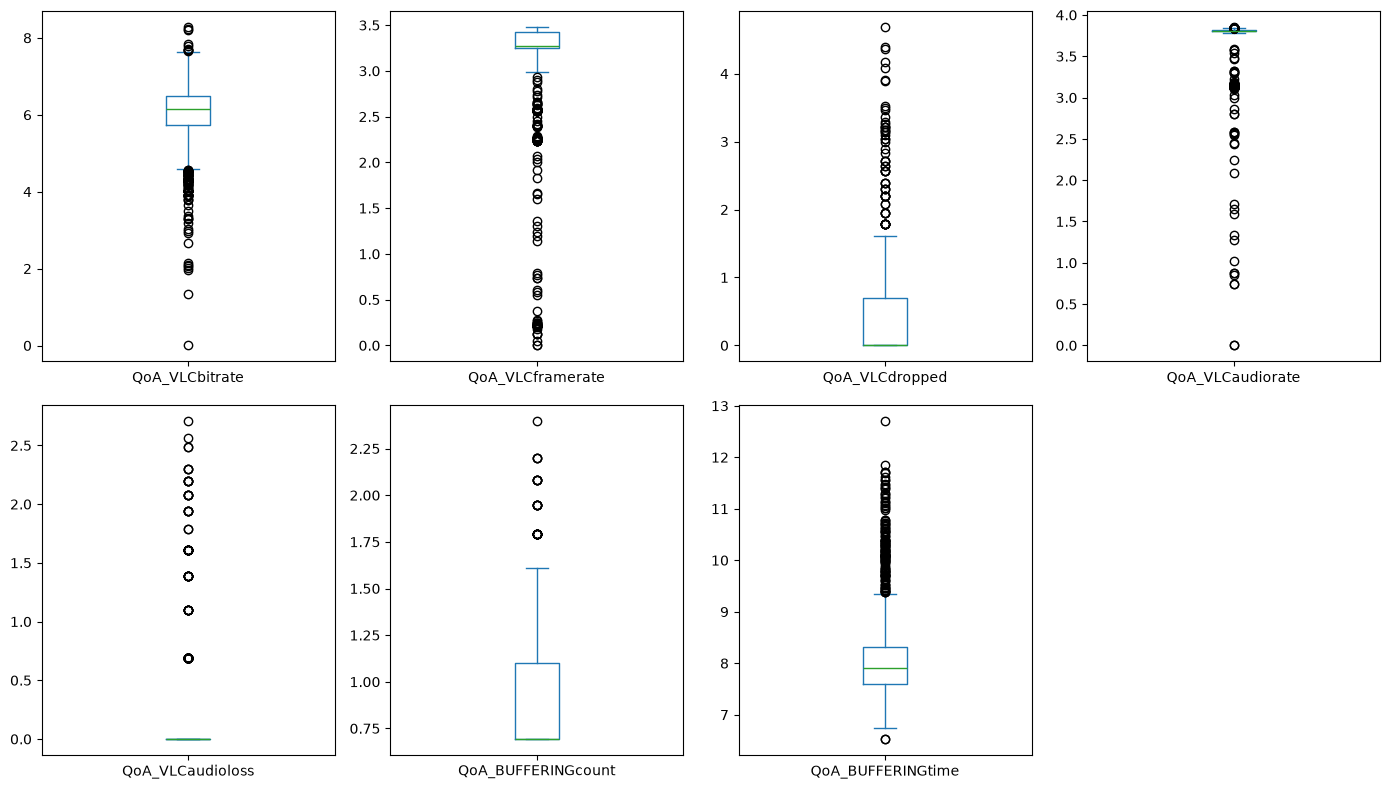

In [16]:
box_plot_cols = ["QoA_VLCbitrate", "QoA_VLCframerate", "QoA_VLCdropped", "QoA_VLCaudiorate",
                   "QoA_VLCaudioloss","QoA_BUFFERINGcount", "QoA_BUFFERINGtime"]
# with logarithmic transformation
df_log = np.log1p(df[box_plot_cols])
df_log.plot(kind="box", subplots=True, layout=(2, 4),
                       figsize=(14, 8), sharey=False)
plt.tight_layout()
plt.show()

#### Analyze the outliers

From the above box plot, data is skewed (we will check more with histogram plot)

Here, we use **logarithmic transformation** to change the relative spacing between points = closer to symmetric/bell-shaped

Purpose: reduce skew, reduce the influence of extreme values, make relationships more linear.

From the original dataset, we have:
- Value (unique) of QoA_BUFFERINGcount: [ 2  1  3  4  5  6  7  8 10]
- Value (unique) of QoA_BUFFERINGtime: [   683    690    840 ... 123430 139610 329271]

Combining with the [Probability density visualization](https://colab.research.google.com/drive/1dmo66IeCzUrVzCabfx7kYQ312SG3P7XL#scrollTo=jdmEZuIli_y9&line=2&uniqifier=1) below, we notice that **QoA_BUFFERINGcount = (8,10)** and **QoA_BUFFERINGtime = 329271** are minor.

Let's check their corresponding MOS to see whether these data points are errors/misktakes or not.

In [17]:
df[df['QoA_BUFFERINGcount'].isin([7, 8, 10])]

,id,user_id,QoA_VLCresolution,QoA_VLCbitrate,QoA_VLCframerate,QoA_VLCdropped,QoA_VLCaudiorate,QoA_VLCaudioloss,QoA_BUFFERINGcount,QoA_BUFFERINGtime,...,QoD_os-version,QoD_api-level,QoU_sex,QoU_age,QoU_Ustedy,QoF_begin,QoF_shift,QoF_audio,QoF_video,MOS
1450,518,62,360,592.73570,23.900000,32,44.033333,0,7,21607,...,4.4.4(suv3Rw),19,1,23,5,2,5,4,4,3
1481,526,63,360,405.40152,28.633333,107,43.116667,0,8,28905,...,4.4.4(suv3Rw),19,1,27,5,1,4,1,2,1
1492,528,63,360,144.45134,24.166667,16,44.250000,0,7,32264,...,4.4.4(suv3Rw),19,1,27,5,1,2,2,2,1
1503,1849,175,360,503.80164,29.916667,58,44.700000,0,8,39053,...,4.4.4(suv3Rw),19,1,52,5,4,5,4,4,2
1509,286,27,360,310.77510,24.416667,25,43.866667,0,7,43530,...,4.1.2(I9300XXELL4),16,1,27,5,3,1,3,4,2
1510,287,28,360,510.35846,24.800000,31,44.083333,1,10,44900,...,4.1.2(I9300XXELL4),16,0,28,5,3,4,2,3,1
1513,529,63,360,438.80896,24.050000,77,44.466667,0,8,47665,...,4.4.4(suv3Rw),19,1,27,5,1,3,2,2,1
1518,64,3,240,221.66985,23.550000,4,21.933333,1,7,60700,...,4.1.2(I9300XXELL4),16,1,27,5,2,2,2,3,2
1523,859,110,360,100.49373,17.183333,24,31.333333,0,7,69478,...,4.3(I9300XXUGNB5),18,1,20,2,4,3,3,4,2


In [18]:
df[df['QoA_BUFFERINGtime'].isin([123430, 139610, 329271])]

,id,user_id,QoA_VLCresolution,QoA_VLCbitrate,QoA_VLCframerate,QoA_VLCdropped,QoA_VLCaudiorate,QoA_VLCaudioloss,QoA_BUFFERINGcount,QoA_BUFFERINGtime,...,QoD_os-version,QoD_api-level,QoU_sex,QoU_age,QoU_Ustedy,QoF_begin,QoF_shift,QoF_audio,QoF_video,MOS
1539,1774,168,360,58.46057,4.250000,4,8.416667,1,4,123430,...,5.0(G900FXXU1BOC2),21,1,27,5,1,1,1,1,1
1540,67,3,360,47.59162,0.133333,1,19.600000,2,3,139610,...,4.1.1(122573.16),16,1,27,5,1,1,1,1,1
1541,1147,128,360,43.52804,6.633333,12,12.133333,0,4,329271,...,4.4.4(suv3Rw),19,1,27,5,1,1,1,1,1


From the inspection, these data have meaningful insights because they got the very low MOS (only 1 and 2)

=> Keep them to preserve the pratical effects

First, create a statistical table to have better overview of the dataset outliers (using transformed dataset)

In [19]:
# with logarithmic transformation
rows = []
for col in df_log.columns:
    s = df_log[col].dropna()
    n = len(s)

    # calculate upper and lower whisker
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr

    # Whiskers = most extreme data points still inside the fences
    inside = s[(s >= lower_fence) & (s <= upper_fence)]
    lower_whisker = inside.min()
    upper_whisker = inside.max()

    # Outliers = points beyond the fences
    outliers = s[(s < lower_fence) | (s > upper_fence)]
    n_out = len(outliers)

    rows.append({
        "column": col,
        "outlier_min": outliers.min() if n_out else np.nan,
        "lower_whisker": lower_whisker,
        "upper_whisker": upper_whisker,
        "outlier_max": outliers.max() if n_out else np.nan,
        "outlier_count": n_out,
        "outlier_proportion": n_out / n,
    })

summary = pd.DataFrame(rows).set_index("column")
print(summary)

                    outlier_min  lower_whisker  upper_whisker  outlier_max  \
column                                                                       
QoA_VLCbitrate         0.003289       4.591208       7.640888     8.273667   
QoA_VLCframerate       0.000000       2.984840       3.475583     2.933857   
QoA_VLCdropped         1.791759       0.000000       1.609438     4.682131   
QoA_VLCaudiorate       0.000000       3.786082       3.839094     3.850148   
QoA_VLCaudioloss       0.693147       0.000000       0.000000     2.708050   
QoA_BUFFERINGcount     1.791759       0.693147       1.609438     2.397895   
QoA_BUFFERINGtime      6.527958       6.734592       9.354268    12.704639   

                    outlier_count  outlier_proportion  
column                                                 
QoA_VLCbitrate                123            0.079767  
QoA_VLCframerate              163            0.105707  
QoA_VLCdropped                 61            0.039559  
QoA_VLCaudiorate 

Significant numbers:
- outliers proportion of QoA_VLCaudiorate ~24%
- outliers proportion of QoA_VLCframerate ~10%

=> Removing them is risky, can shrink the dataset and make the dataset bias

Then, Let's check the skewness values of the dataset on selected columns and their visualizations

In [20]:
df[box_plot_cols].skew().sort_values(ascending=False)

QoA_VLCdropped        11.028255
QoA_BUFFERINGtime      9.877260
QoA_VLCaudioloss       6.667924
QoA_BUFFERINGcount     3.821554
QoA_VLCbitrate         2.704720
QoA_VLCaudiorate      -2.015143
QoA_VLCframerate      -2.240628
dtype: float64

In [21]:
# with logarithmic transformation
df_log.skew().sort_values(ascending=False)

QoA_VLCaudioloss      4.412878
QoA_VLCdropped        2.763874
QoA_BUFFERINGcount    2.260427
QoA_BUFFERINGtime     1.793272
QoA_VLCbitrate       -1.561844
QoA_VLCframerate     -4.020366
QoA_VLCaudiorate     -4.491847
dtype: float64

Observations:

`QoA_BUFFERINGcount, QoA_BUFFERINGtime` since being transformed have had a better distribution, combining with the observation in [this cell](https://colab.research.google.com/drive/1dmo66IeCzUrVzCabfx7kYQ312SG3P7XL#scrollTo=ZH8MiBqR6ZDo&line=3&uniqifier=1) => good

`VLCdropped, VLCaudioloss` are still highly skewed eventhough they're reduced

=> mostly zero + occasional event - reasonable since within normal network condition, dropped frames and audio are occasional => keep the events to preserve the reality

`VLCframerate, VLCaudiorate, VLCbitrate` are negatively skewed and log1p made `VLCframerate, VLCaudiorate` worse: -2.24 -> -4.02, -2.01 -> -4.49

=> consider to use another transformation

In [22]:
# try PowerTransformer() to handle negative skewness (lef-skewness)
pt = PowerTransformer(method="yeo-johnson")  # default; handles 0s and negatives

df_pt = df.copy()
df_pt[box_plot_cols] = pt.fit_transform(df_pt[box_plot_cols])
df_pt[box_plot_cols].skew().sort_values(ascending=False)

QoA_VLCaudioloss      3.154957
QoA_BUFFERINGcount    1.124416
QoA_VLCdropped        0.683630
QoA_VLCbitrate        0.092534
QoA_BUFFERINGtime     0.025815
QoA_VLCframerate     -0.786687
QoA_VLCaudiorate     -1.568467
dtype: float64

### Histogram

Check the probability density

In [23]:
# Frequency per value of a column
# df["QoA_BUFFERINGcount"].value_counts().sort_index()
# df["QoA_BUFFERINGtime"].value_counts().sort_index()
df["QoA_VLCresolution"].value_counts().sort_index()

QoA_VLCresolution
240      67
360    1475
Name: count, dtype: int64

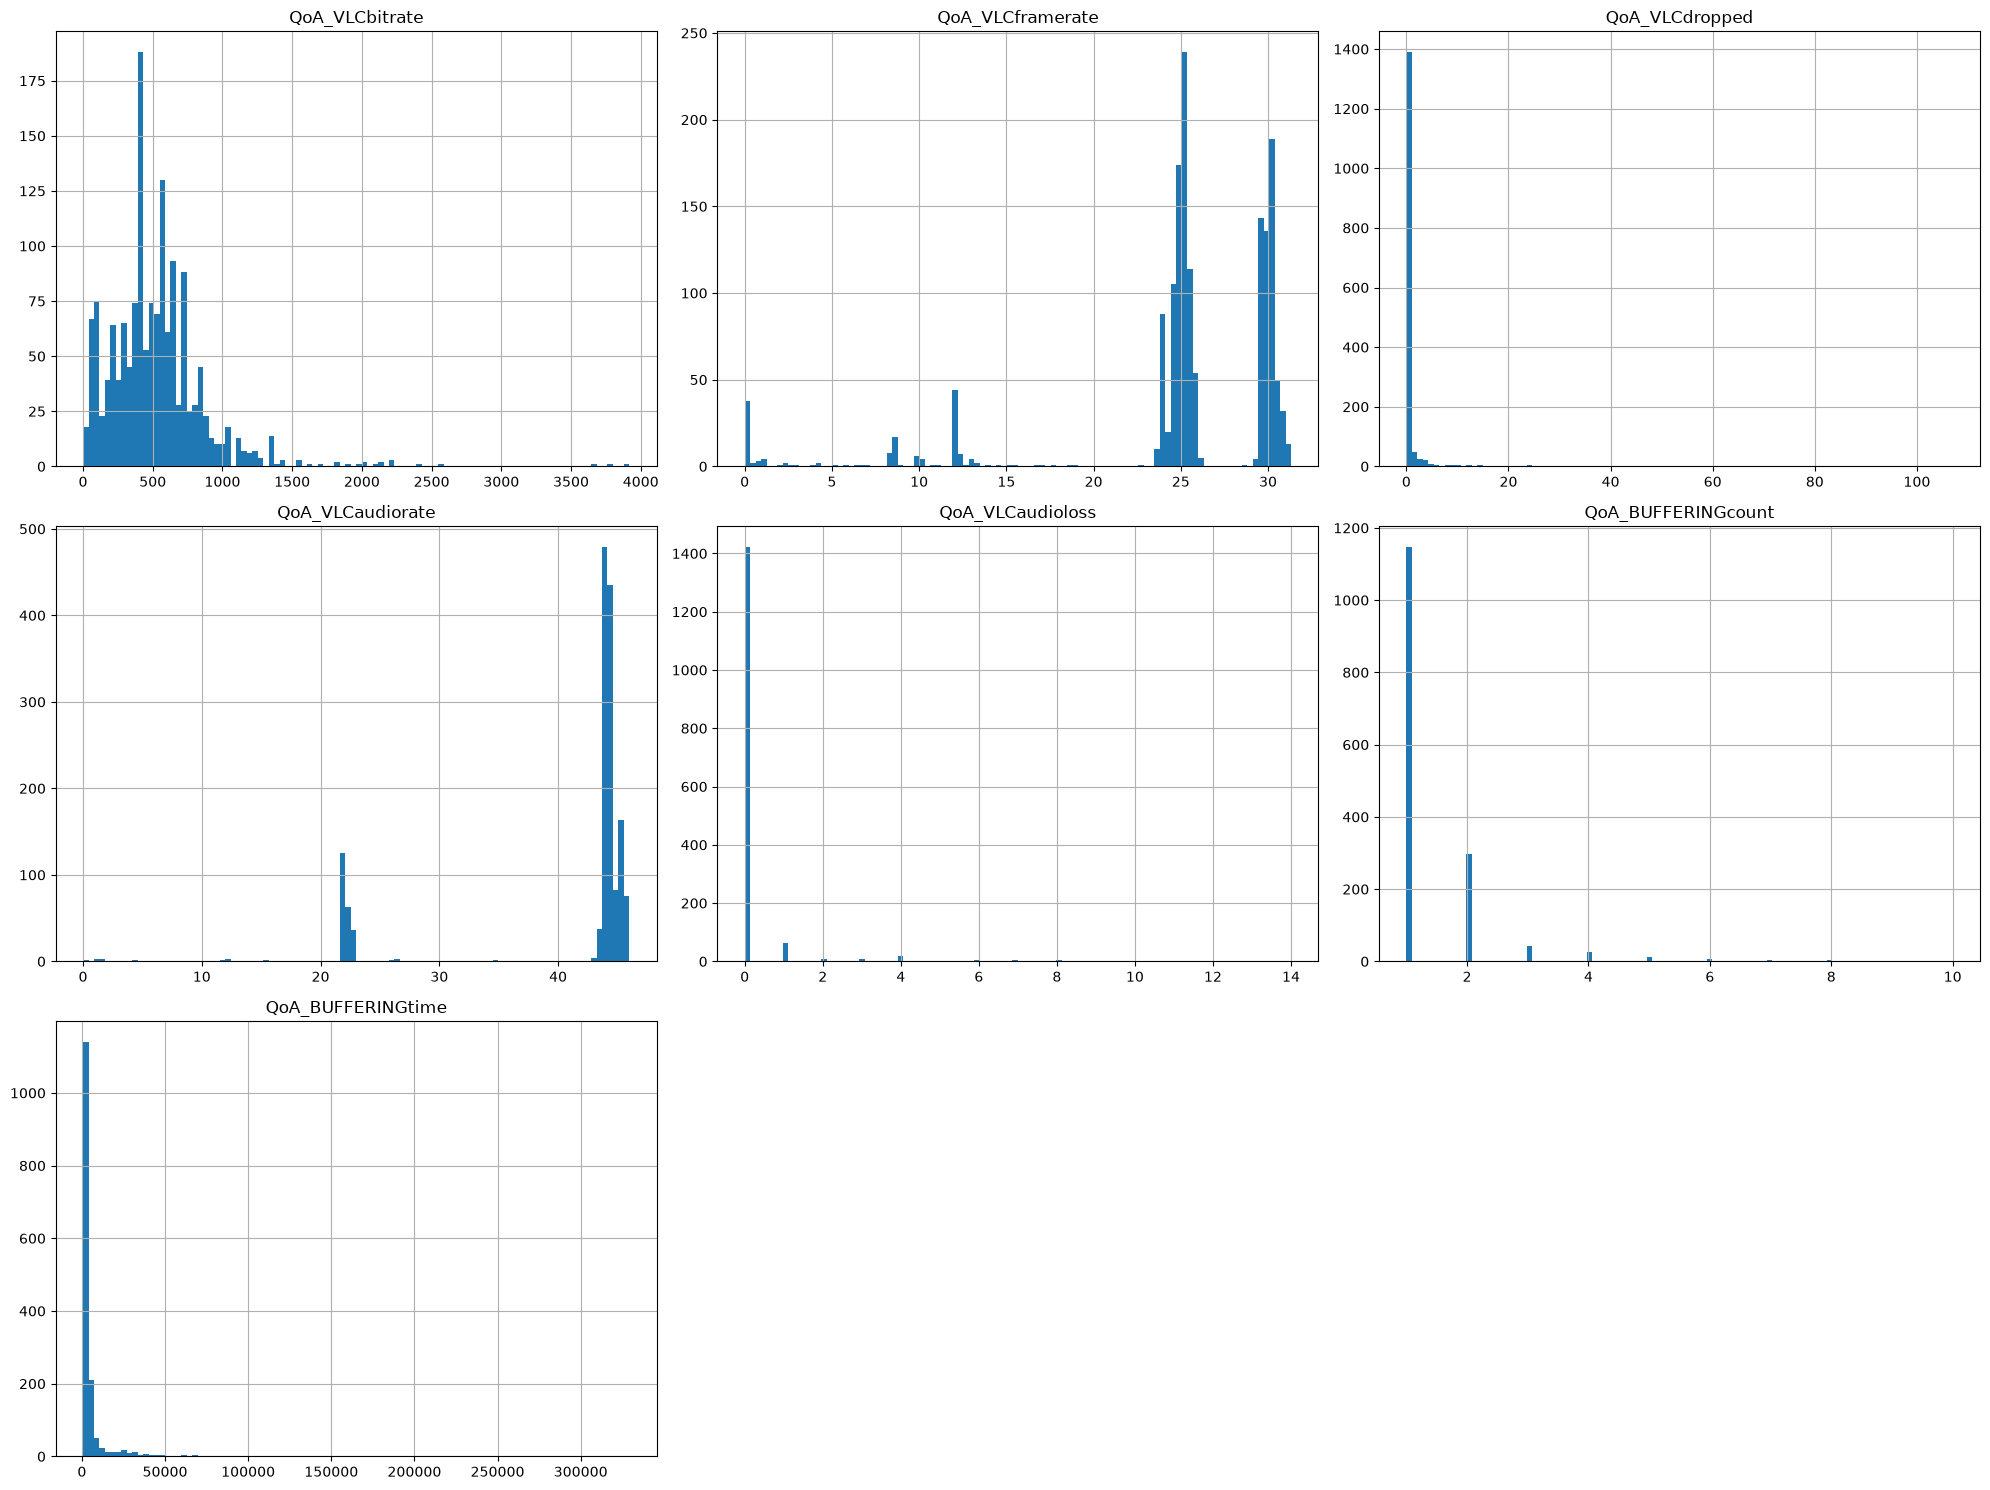

In [24]:
# Check the probability density (skewness as well)
df[box_plot_cols] \
    .hist(bins=100, figsize=(20, 15))
plt.tight_layout()
plt.show()

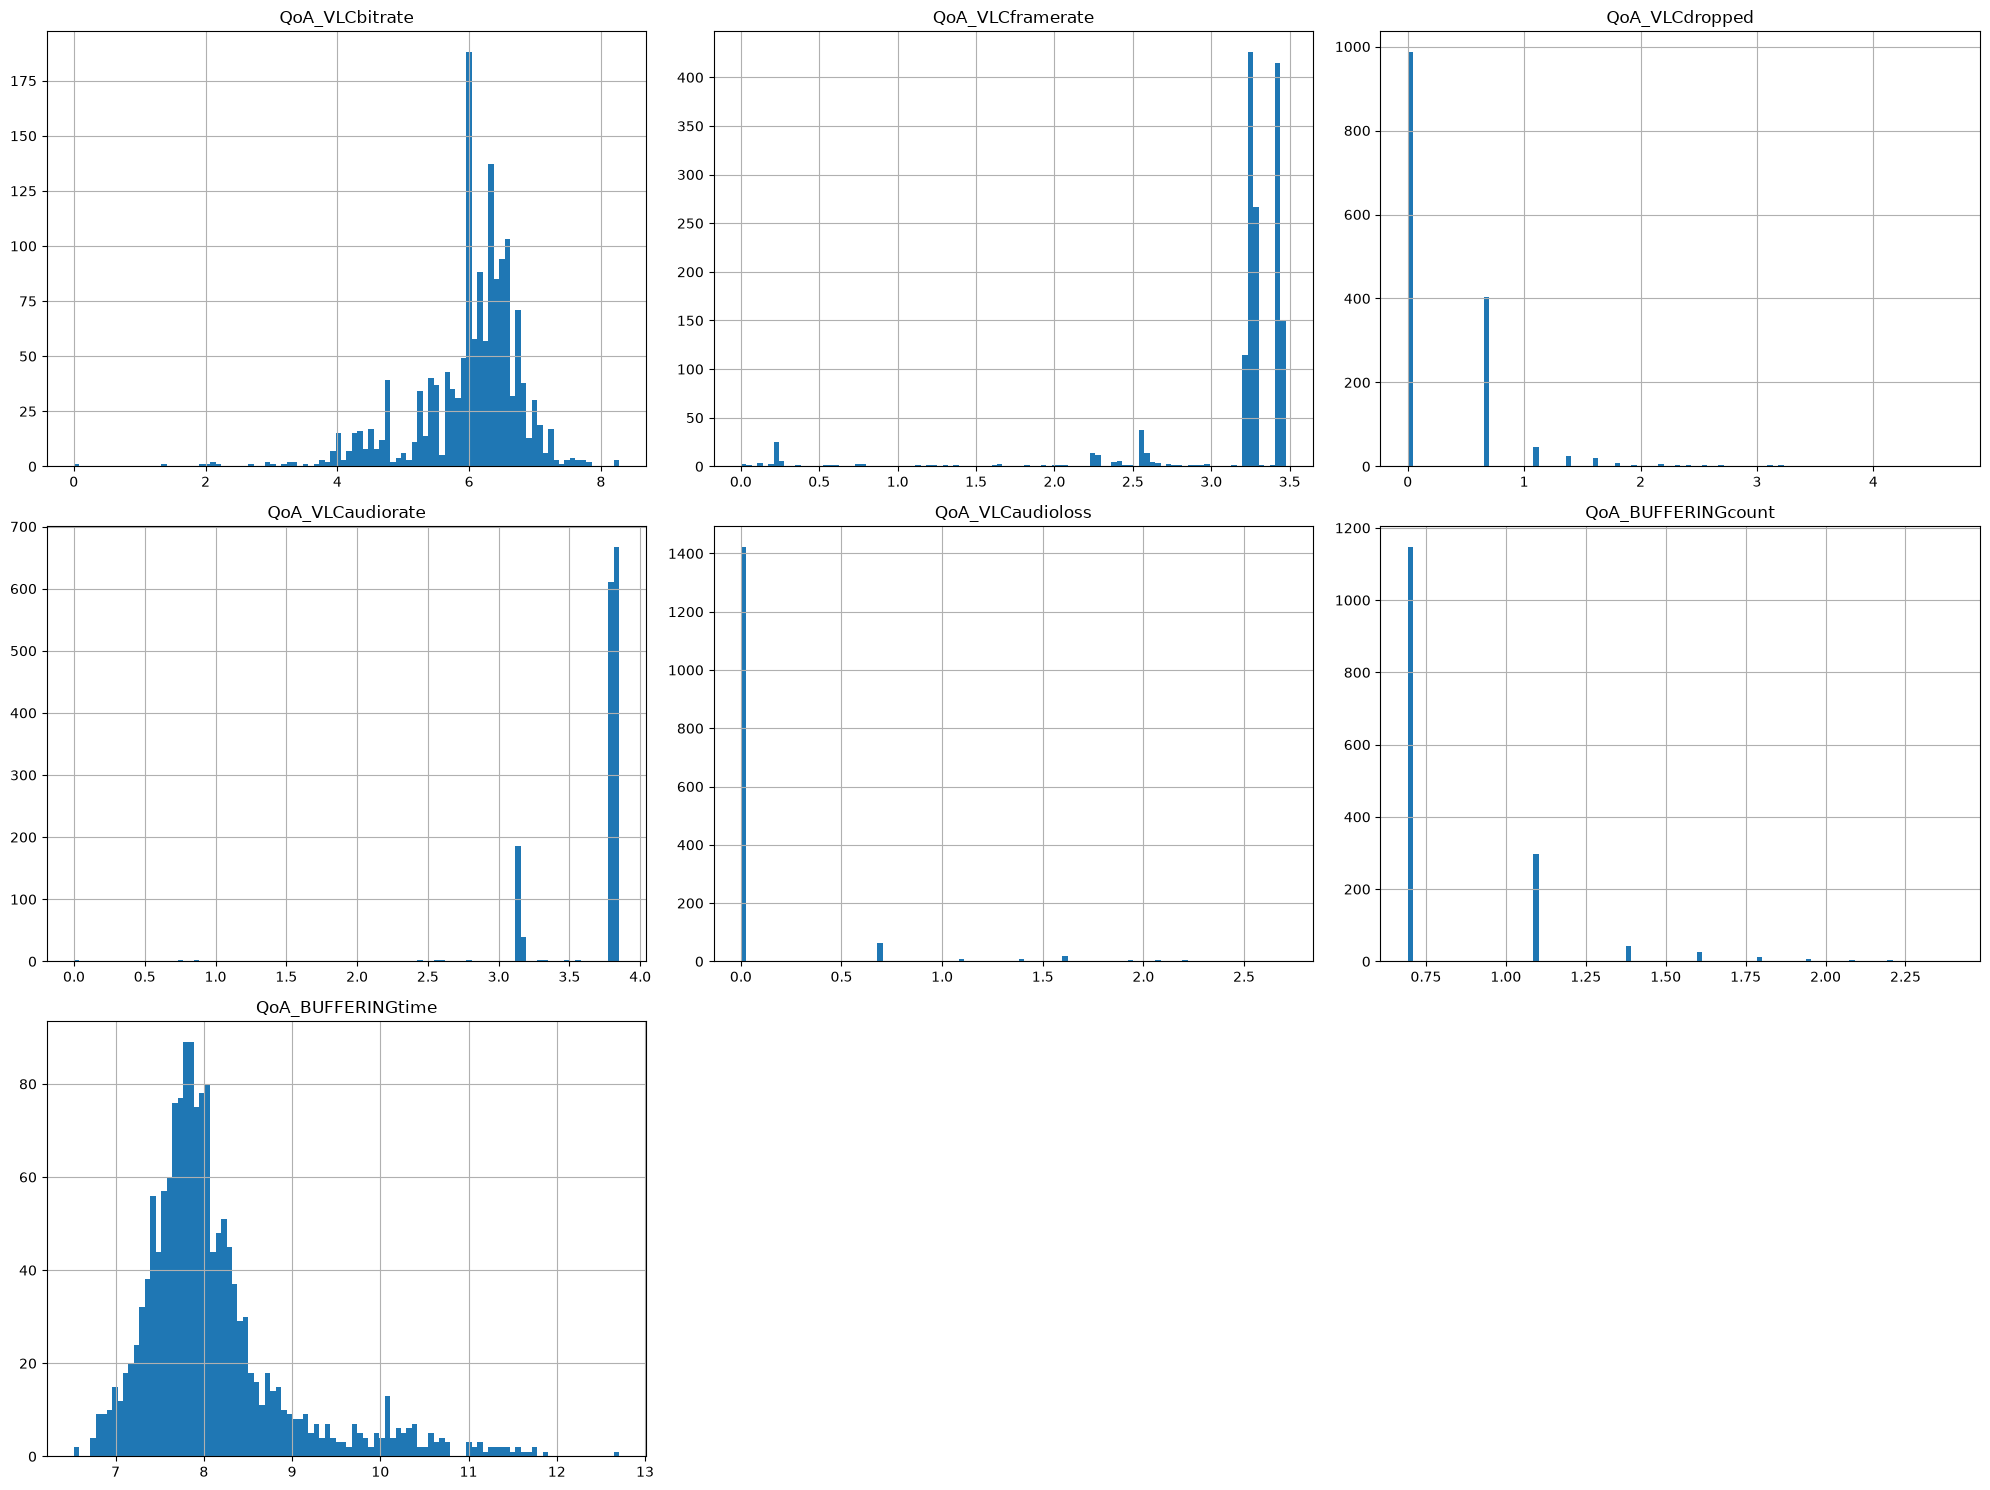

In [25]:
# with logarithmic transformation
df_log \
    .hist(bins=100, figsize=(20, 15))
plt.tight_layout()
plt.show()

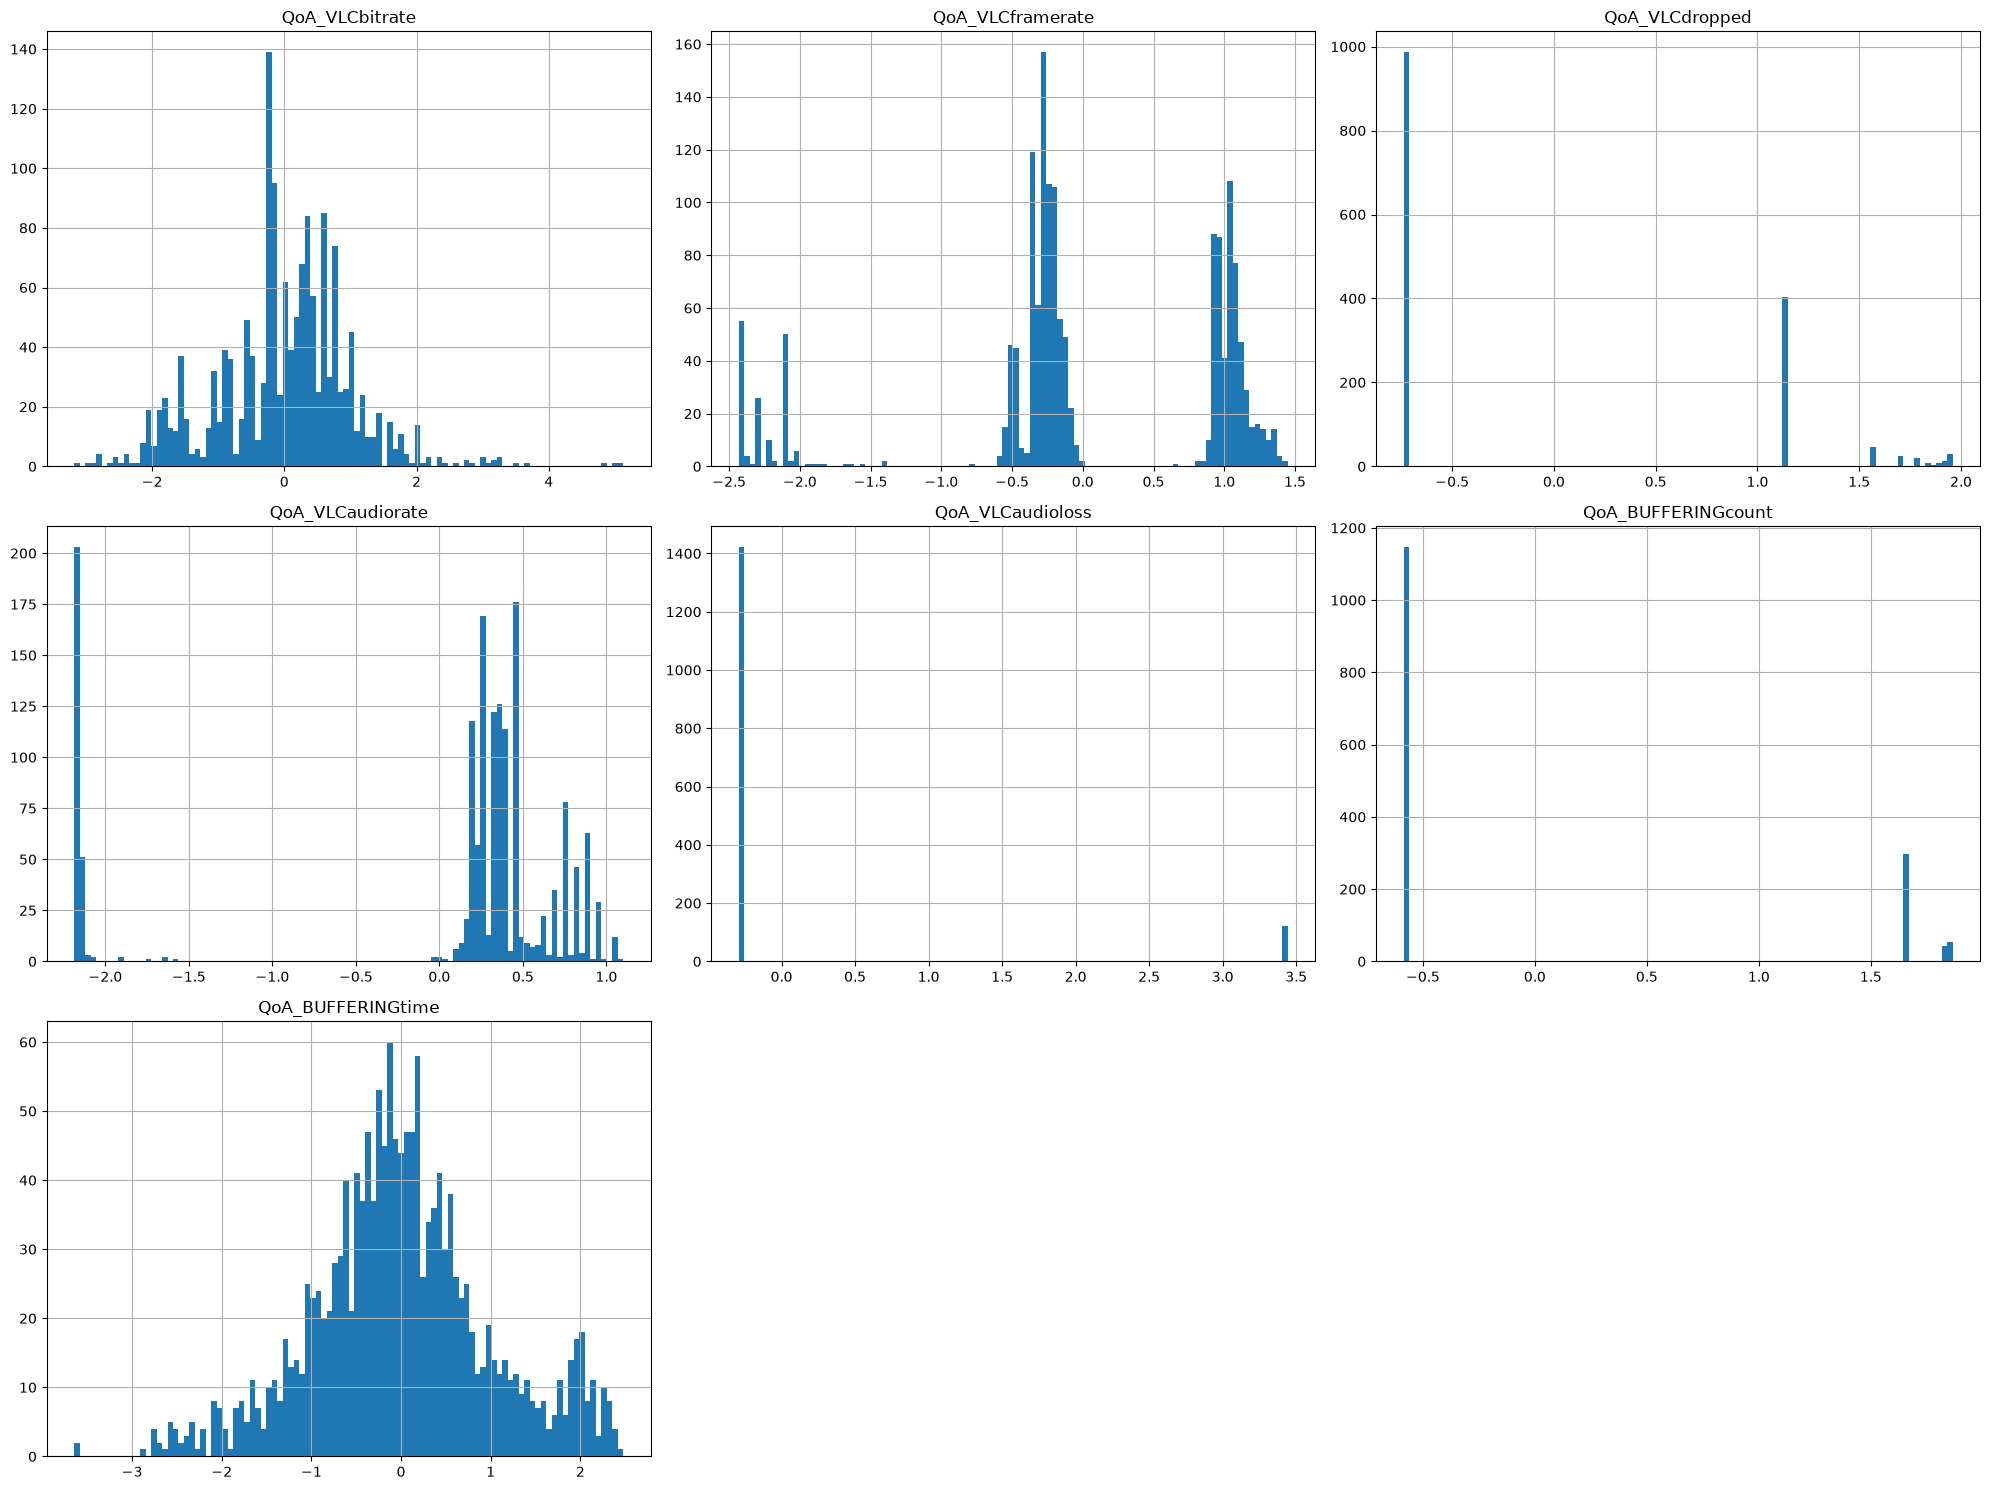

In [26]:
# with PowerTransformer("yeo-johnson") transformation
df_pt \
    .hist(column=box_plot_cols, bins=100, figsize=(20, 15))
plt.tight_layout()
plt.show()

### Group By

How does the distribution of a feature changes with the quality?

array([[<Axes: title={'center': '1'}>, <Axes: title={'center': '2'}>],
       [<Axes: title={'center': '3'}>, <Axes: title={'center': '4'}>],
       [<Axes: title={'center': '5'}>, <Axes: >]], dtype=object)

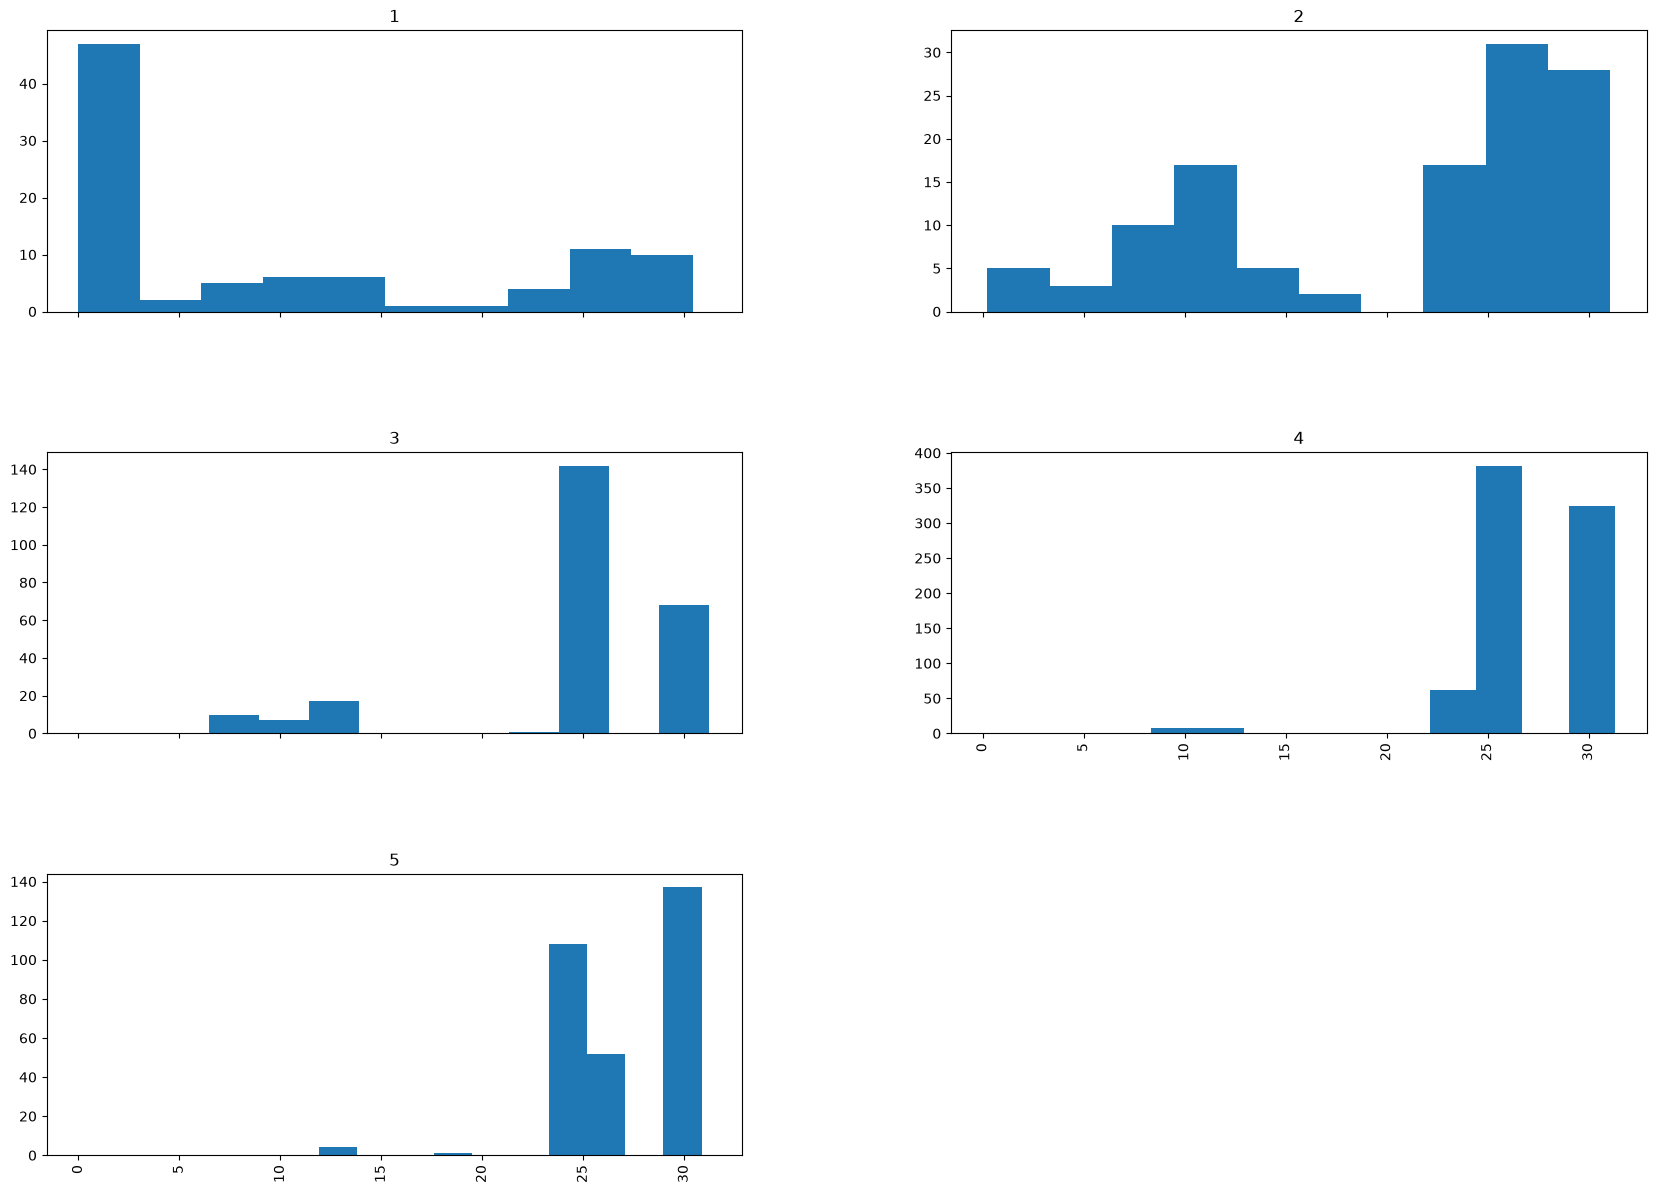

In [27]:
# 1. QoA_VLCframerate by QoA_VLCresolution
df[["QoA_VLCframerate", "MOS"]] \
    .hist(bins=10, column='QoA_VLCframerate', by='MOS', figsize=(20, 15), sharex=True)

Does it mean the higher frame rate, the higher MOS? **No**
- Not too clear, although MOS 3,4,5 reach higher maximum framerates, MOS 1,2 does too

array([[<Axes: title={'center': '1'}>, <Axes: title={'center': '2'}>],
       [<Axes: title={'center': '3'}>, <Axes: title={'center': '4'}>],
       [<Axes: title={'center': '5'}>, <Axes: >]], dtype=object)

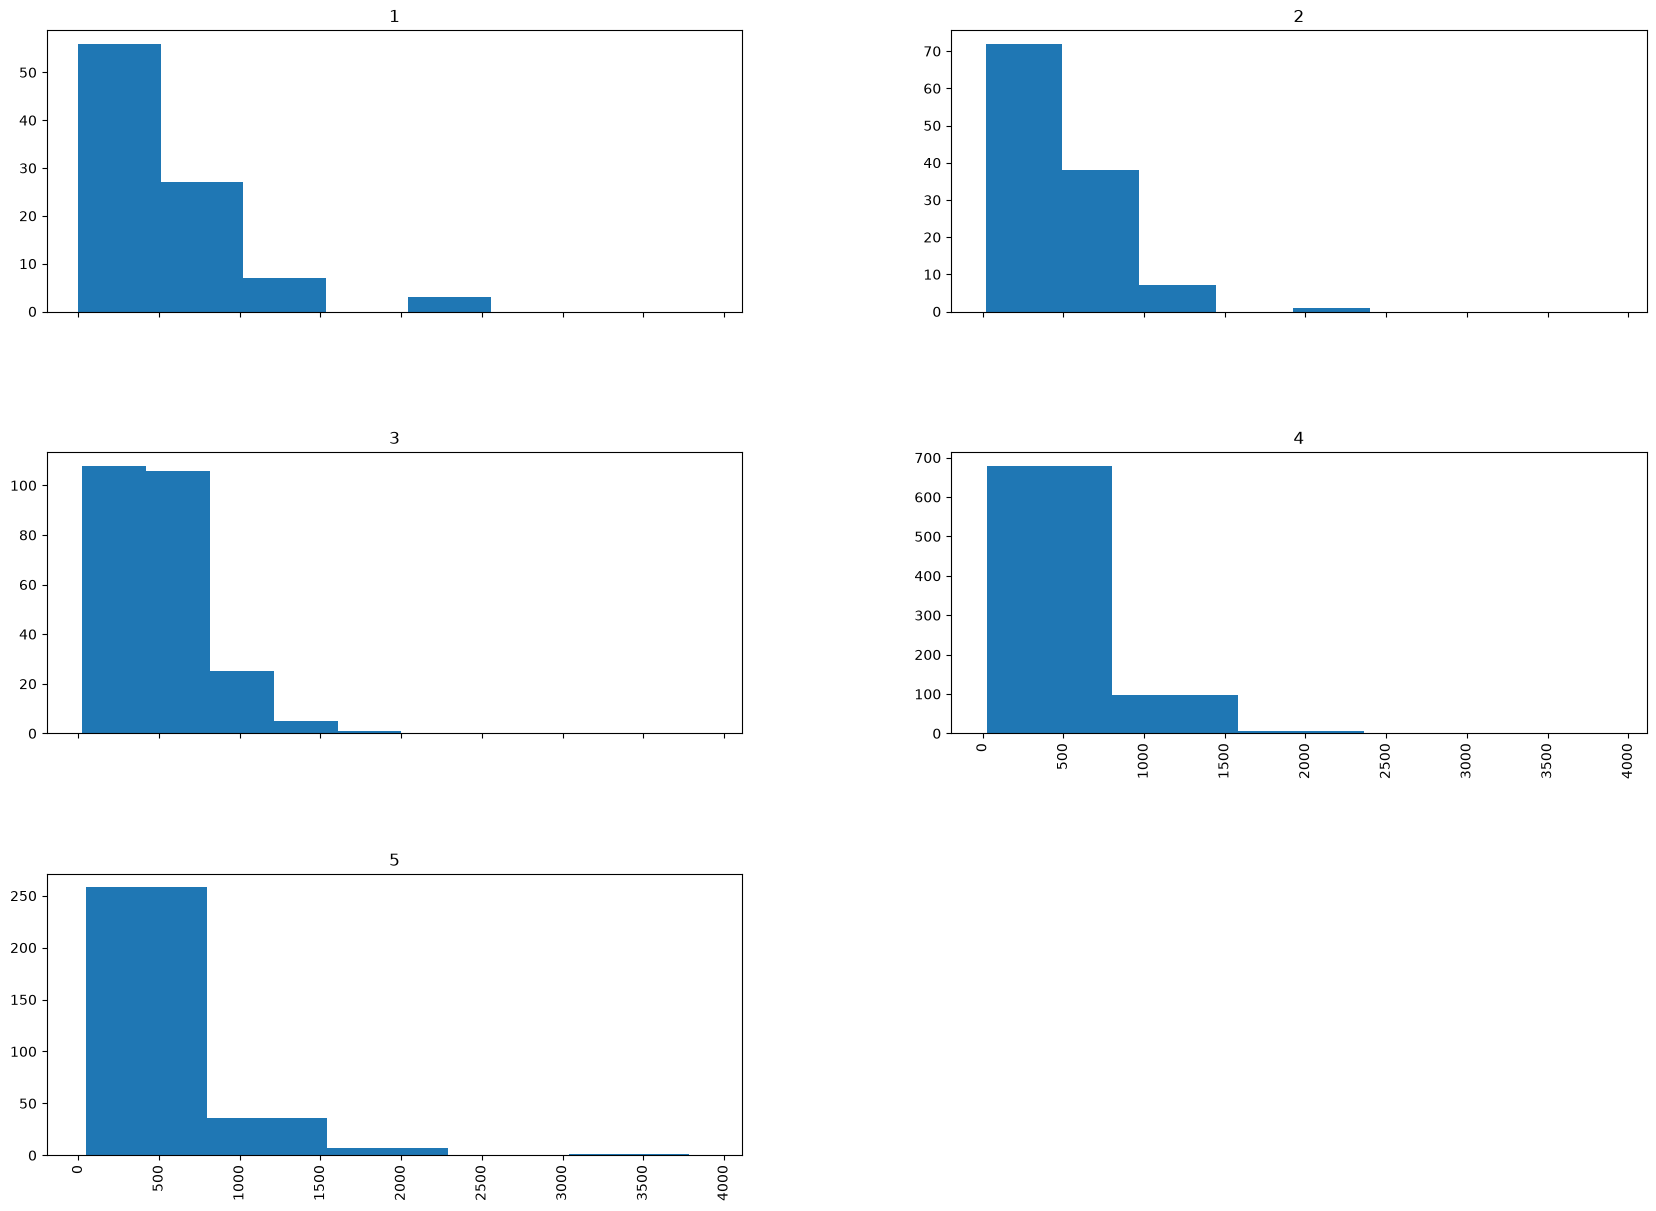

In [28]:
# 2. QoA_VLCbitrate by MOS
df[["QoA_VLCbitrate", "MOS"]] \
    .hist(bins=5, column='QoA_VLCbitrate', by='MOS', figsize=(20, 15), sharex=True)

# df.hist(column='QoA_VLCbitrate', by='QoA_VLCresolution',
#         bins=50, figsize=(20, 10), sharex=True)

For bitrate grouped by MOS, the distributions across 5 MOS are nearly the same, which is all dense at the low end

array([[<Axes: title={'center': '1'}>, <Axes: title={'center': '2'}>],
       [<Axes: title={'center': '3'}>, <Axes: title={'center': '4'}>],
       [<Axes: title={'center': '5'}>, <Axes: >]], dtype=object)

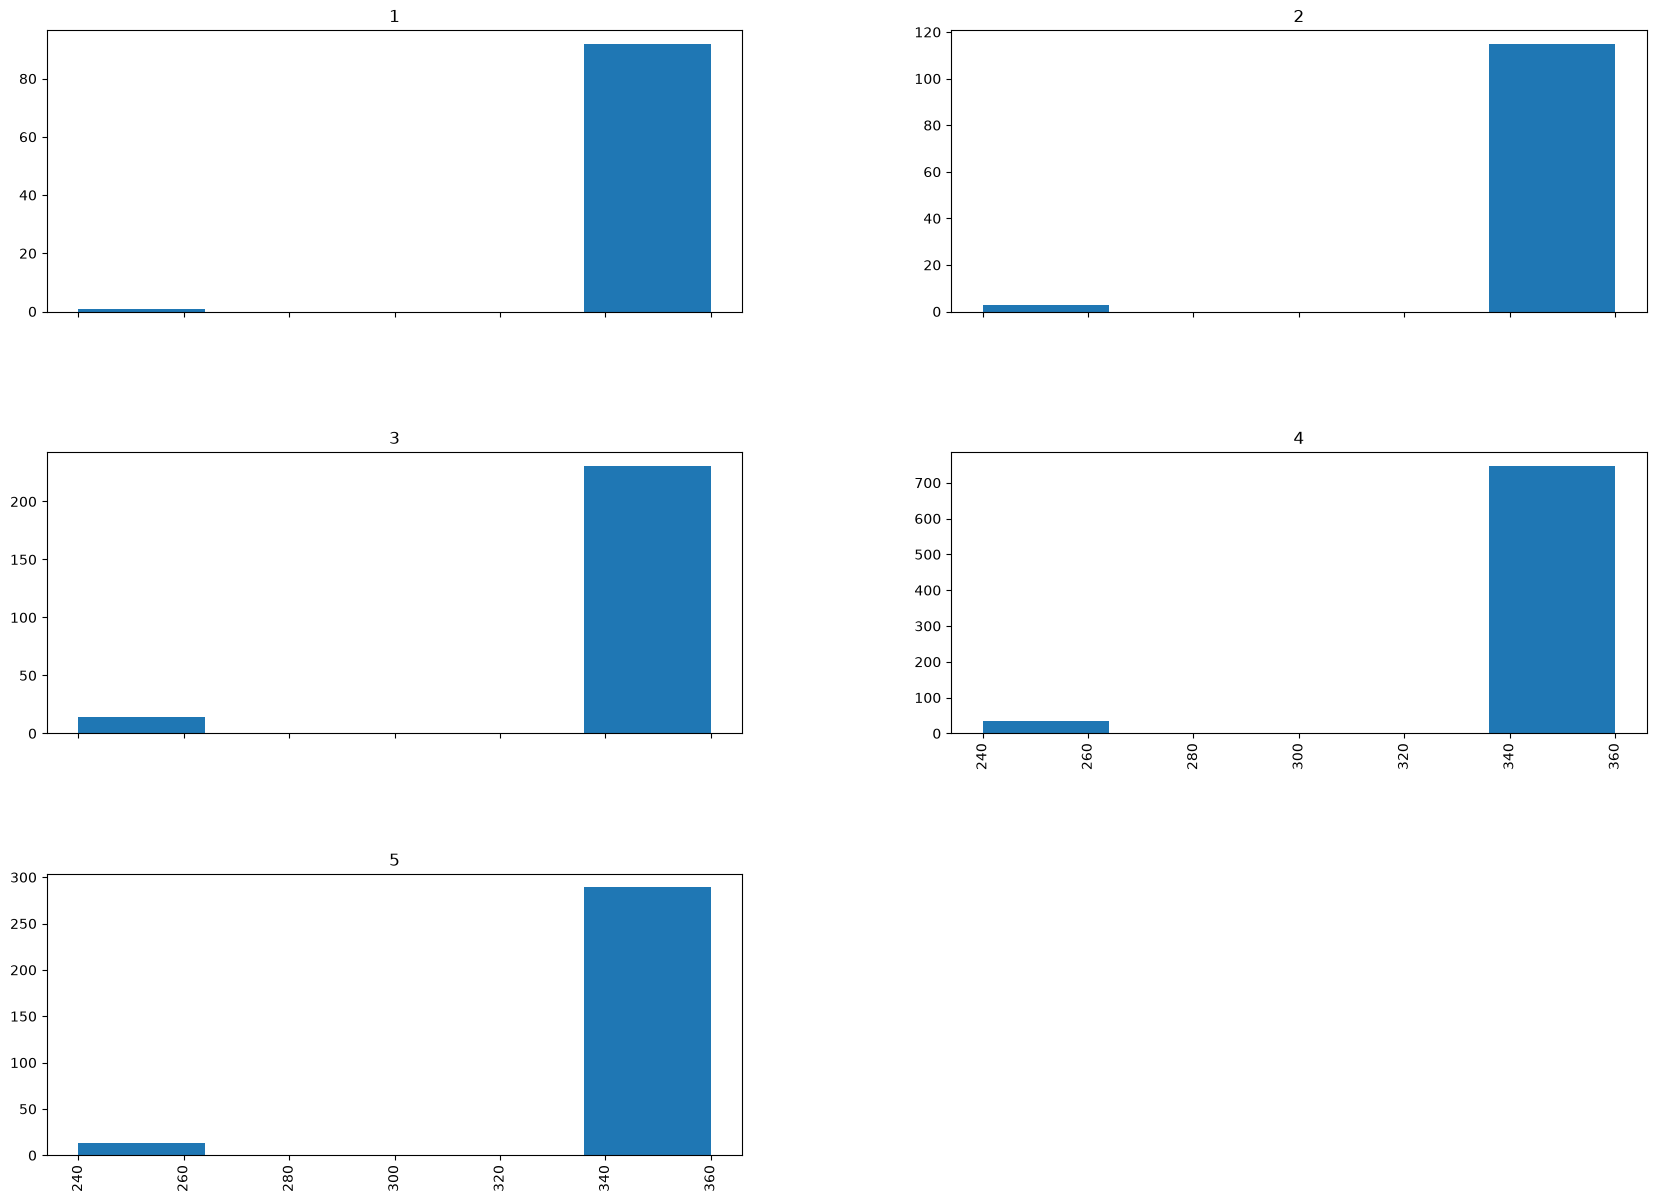

In [29]:
# 3. QoA_VLCresolution by MOS
df[["QoA_VLCresolution", "MOS"]] \
    .hist(bins=5, column='QoA_VLCresolution', by='MOS', figsize=(20, 15), sharex=True)

Not too much information between the relationship.

array([[<Axes: title={'center': '1'}>, <Axes: title={'center': '2'}>],
       [<Axes: title={'center': '3'}>, <Axes: title={'center': '4'}>],
       [<Axes: title={'center': '5'}>, <Axes: >]], dtype=object)

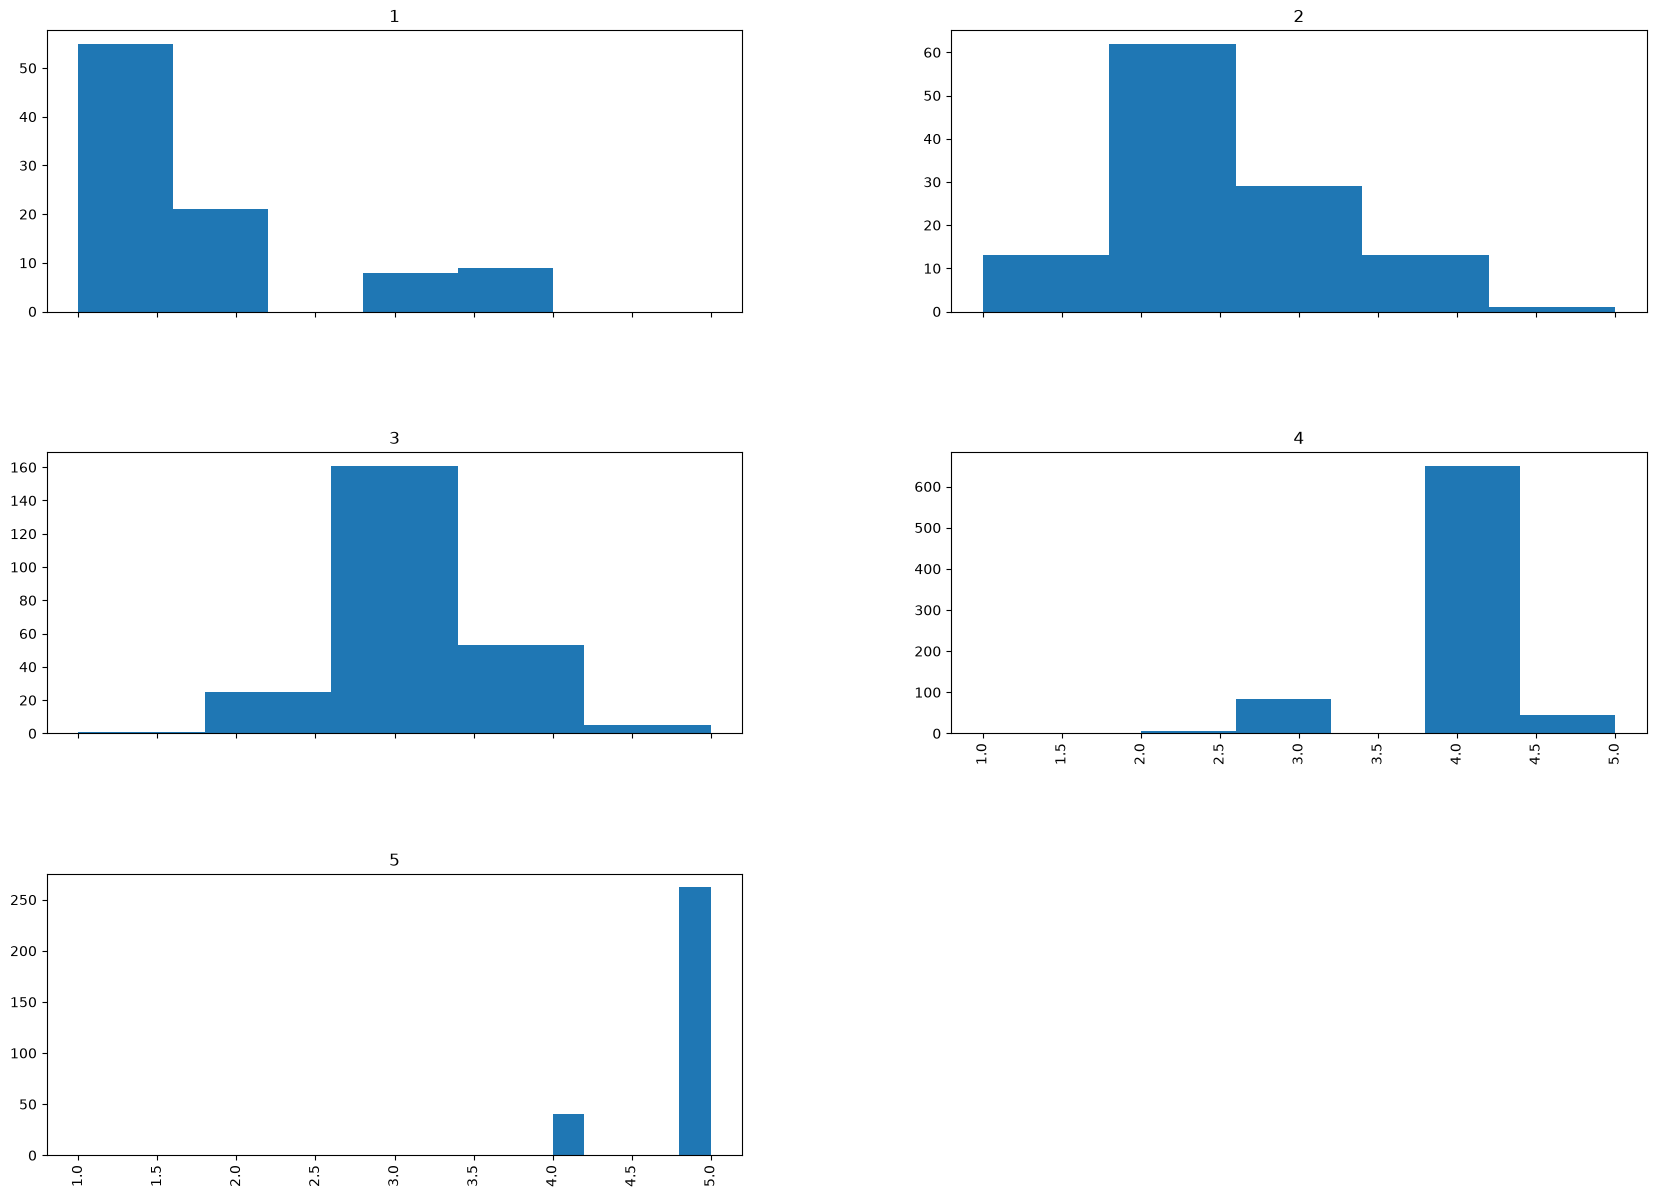

In [30]:
# 4. QoF_audio by MOS
df[["QoF_audio", "MOS"]] \
    .hist(bins=5, column='QoF_audio', by='MOS', figsize=(20, 15), sharex=True)

array([[<Axes: title={'center': '1'}>, <Axes: title={'center': '2'}>],
       [<Axes: title={'center': '3'}>, <Axes: title={'center': '4'}>],
       [<Axes: title={'center': '5'}>, <Axes: >]], dtype=object)

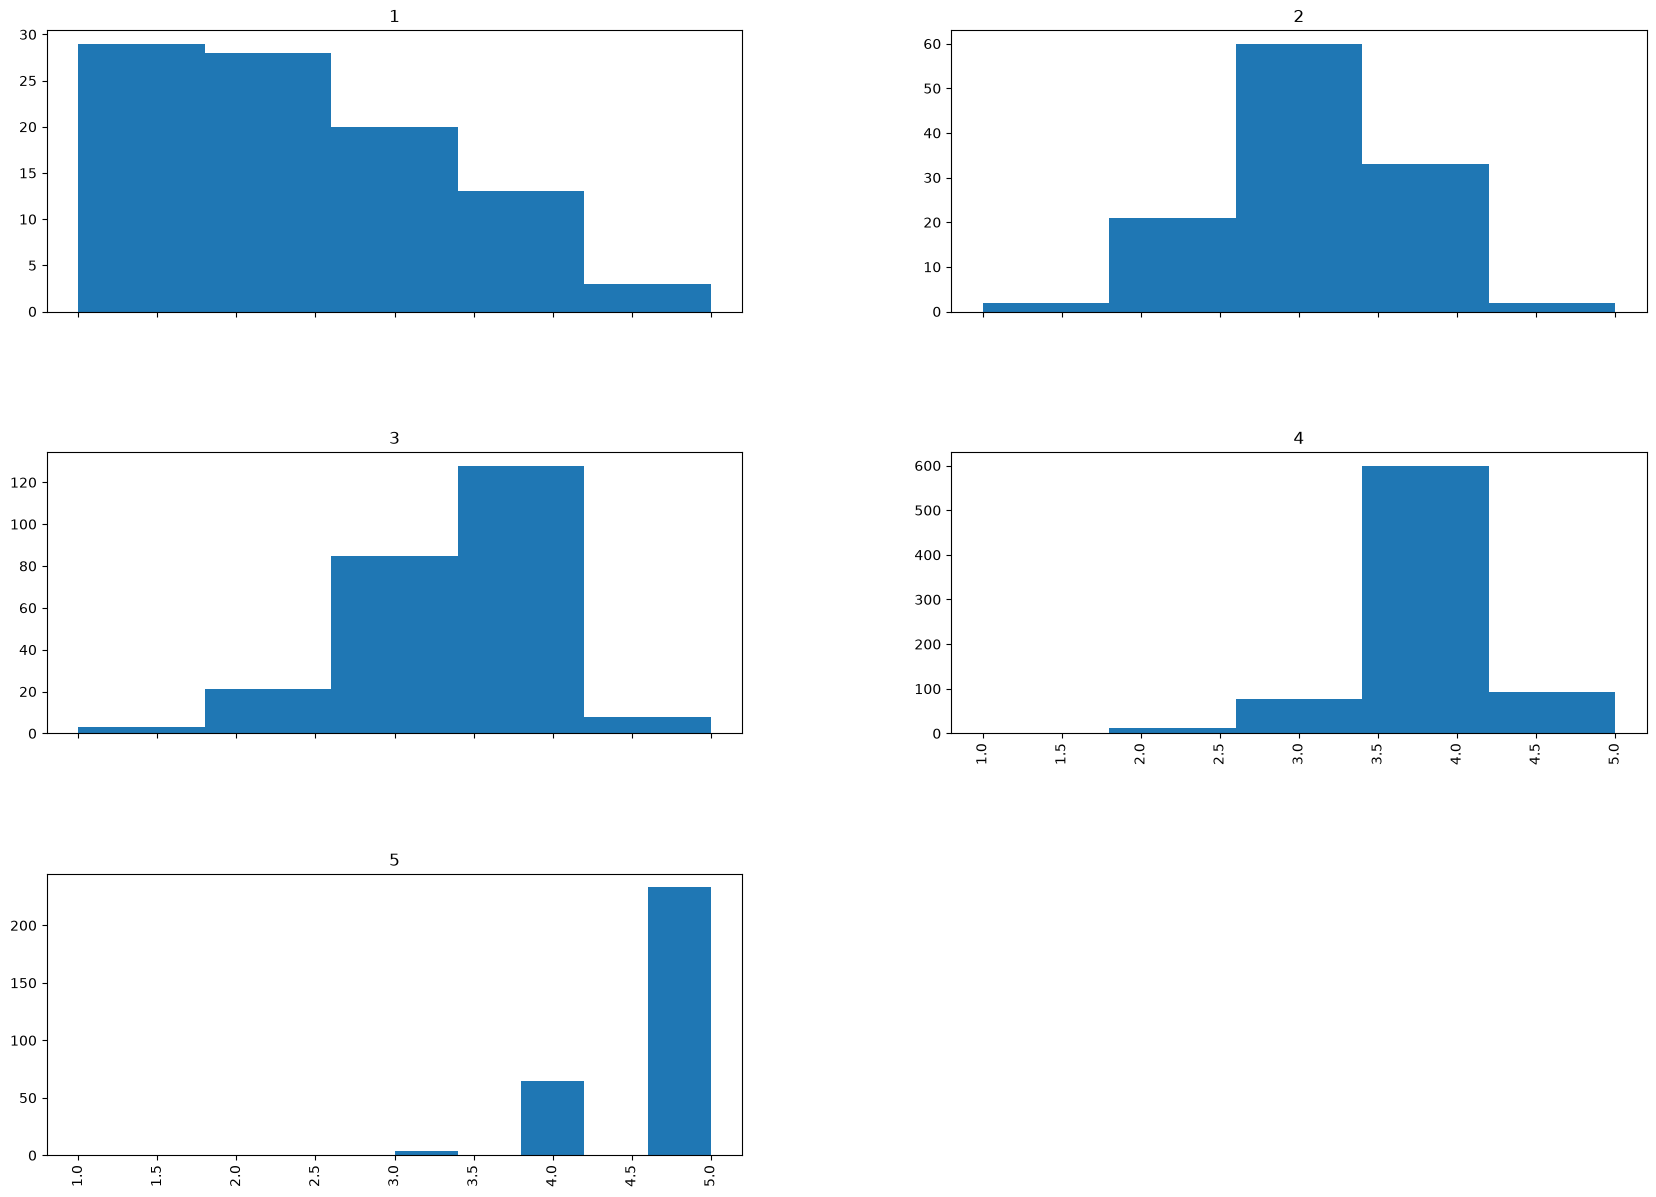

In [31]:
# 5. QoF_video by MOS
df[["QoF_video", "MOS"]] \
    .hist(bins=5, column='QoF_video', by='MOS', figsize=(20, 15), sharex=True)

array([[<Axes: title={'center': '1'}>, <Axes: title={'center': '2'}>],
       [<Axes: title={'center': '3'}>, <Axes: title={'center': '4'}>],
       [<Axes: title={'center': '5'}>, <Axes: >]], dtype=object)

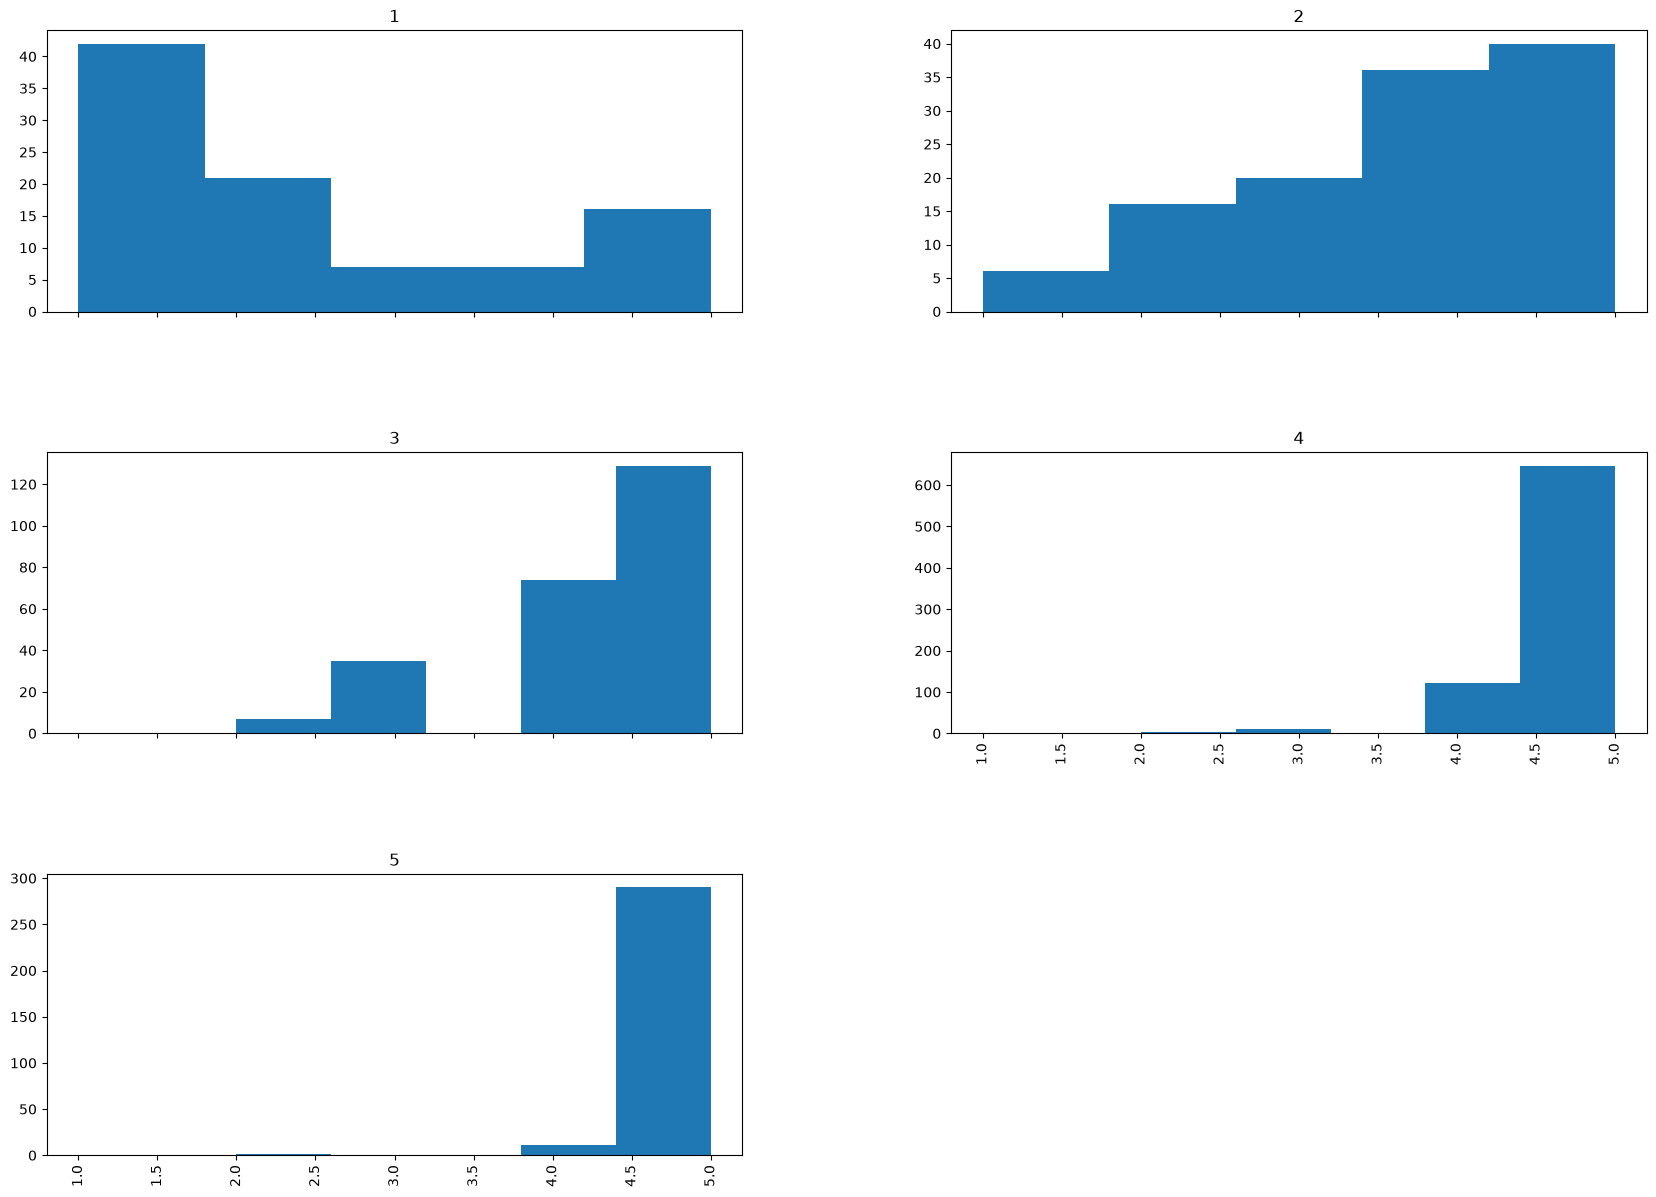

In [32]:
# 6. QoF_shift by MOS
df[["QoF_shift", "MOS"]] \
    .hist(bins=5, column='QoF_shift', by='MOS', figsize=(20, 15), sharex=True)

array([[<Axes: title={'center': '1'}>, <Axes: title={'center': '2'}>],
       [<Axes: title={'center': '3'}>, <Axes: title={'center': '4'}>],
       [<Axes: title={'center': '5'}>, <Axes: >]], dtype=object)

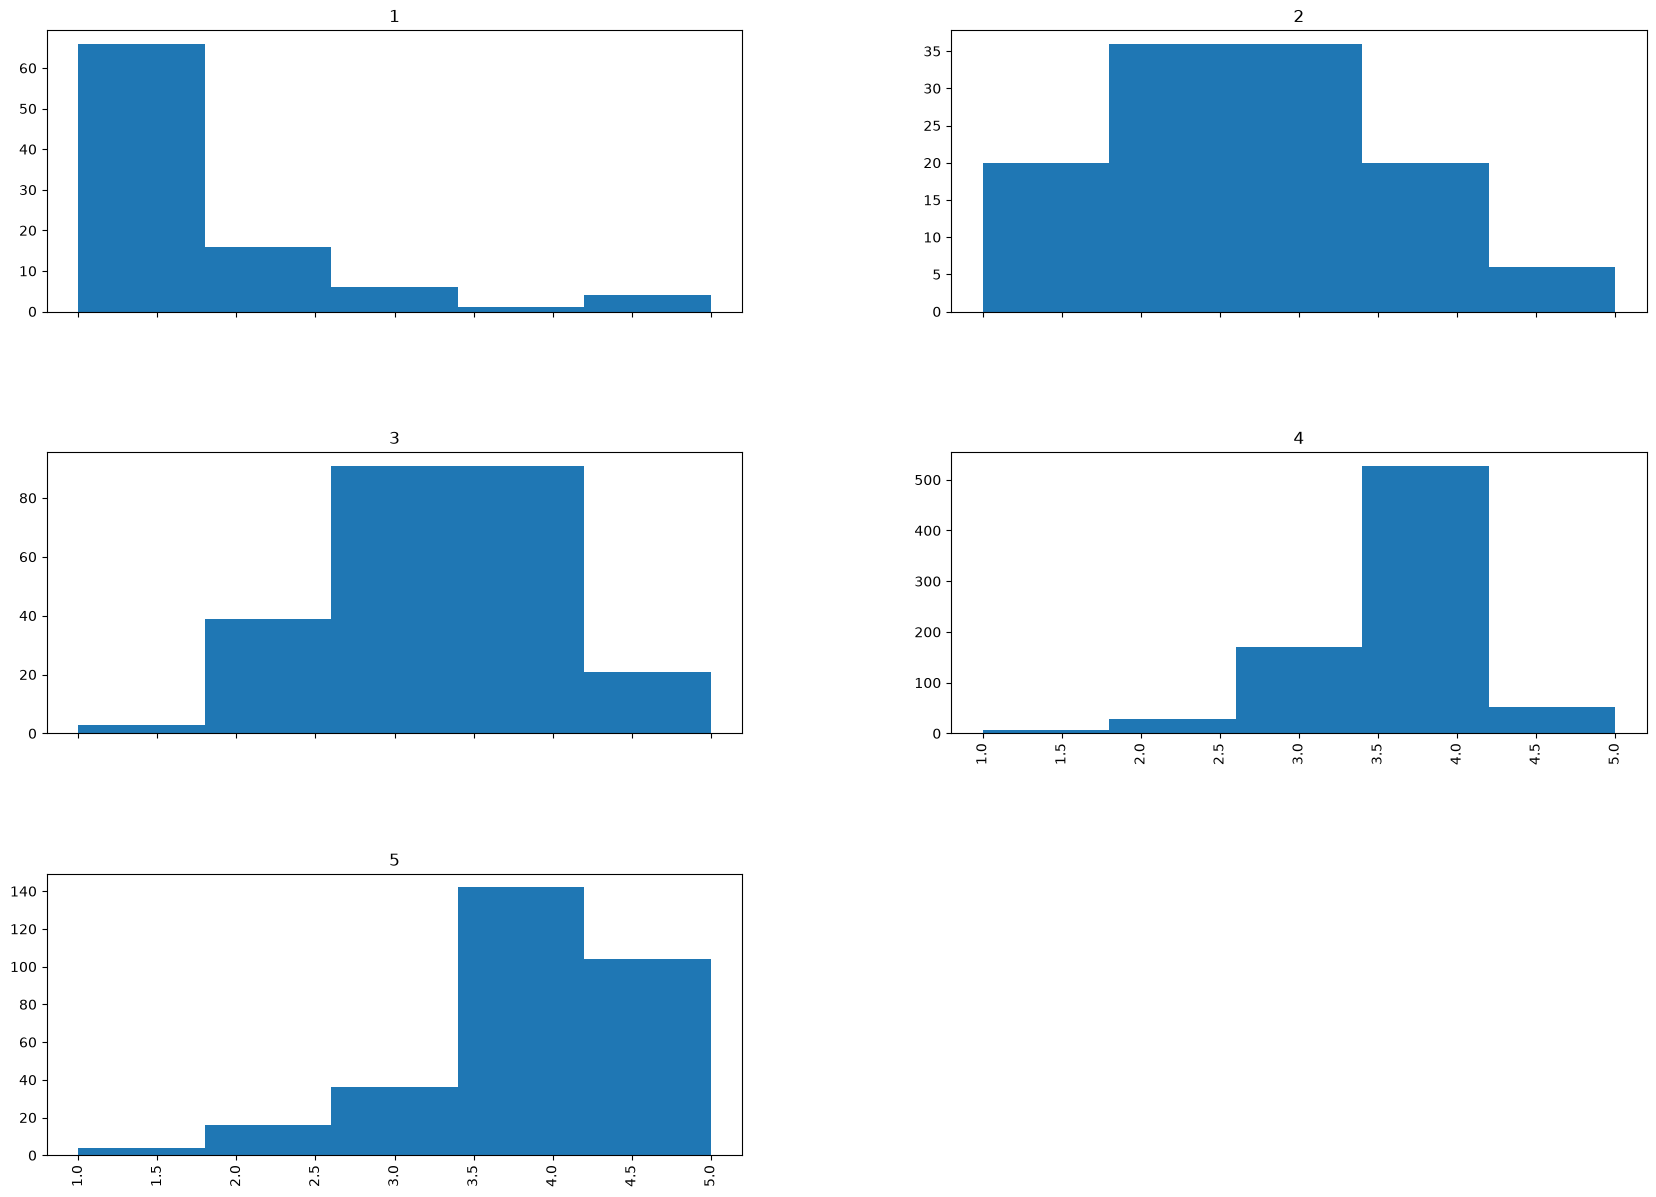

In [33]:
# 7. QoF_begin by MOS
df[["QoF_begin", "MOS"]] \
    .hist(bins=5, column='QoF_begin', by='MOS', figsize=(20, 15), sharex=True)

We can see that the better feedback on Audio, Video, Begin Time, Quality Shifting, the higher MOS

Combining the fact that QoF_* features are also subjective user ratings (1-5) and our above observations, QoF_* features are probably the restatement of MOS. Therefore, we can drop them to avoid data leakage

## Check Correlation

Correlation: how do features relate to each other

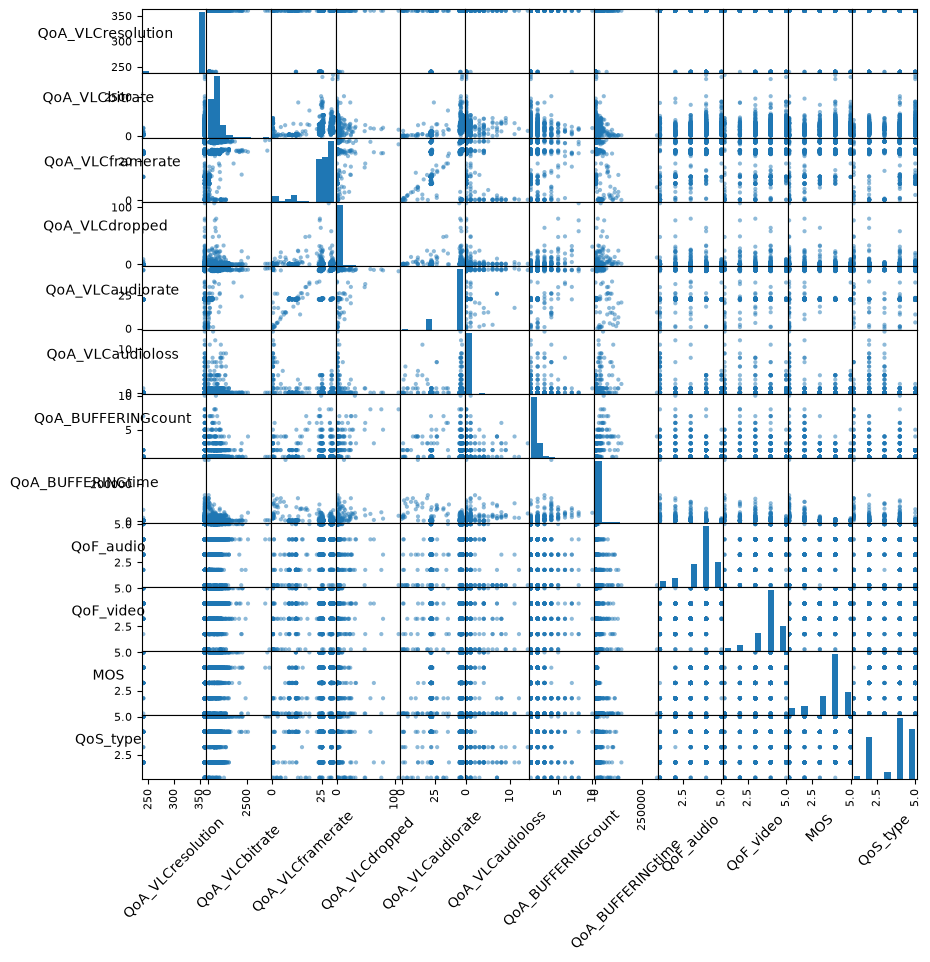

In [34]:
corr_plot_cols = ['QoA_VLCresolution','QoA_VLCbitrate',
                  'QoA_VLCframerate', 'QoA_VLCdropped',
                  'QoA_VLCaudiorate', 'QoA_VLCaudioloss',
                  'QoA_BUFFERINGcount', 'QoA_BUFFERINGtime',
                  'QoF_audio', 'QoF_video',
                  'MOS', 'QoS_type']
sm = scatter_matrix(df[corr_plot_cols],
                   figsize=(10,10))
# sm = scatter_matrix(df.drop(columns=['id', 'user_id']), figsize=(20,20))
visualization.rotate_labels(sm)
plt.show()

In [35]:
def print_corr(corr_matrix, col_1: str, col_2: str):
  print(f"{col_1} <-> {col_2}:",
    corr_matrix[col_1][col_2])

corr_matrix = df[corr_plot_cols].corr().round(2)
corr_matrix

,QoA_VLCresolution,QoA_VLCbitrate,QoA_VLCframerate,QoA_VLCdropped,QoA_VLCaudiorate,QoA_VLCaudioloss,QoA_BUFFERINGcount,QoA_BUFFERINGtime,QoF_audio,QoF_video,MOS,QoS_type
QoA_VLCresolution,1.00,0.24,0.05,0.03,0.41,0.04,0.05,0.04,-0.01,-0.02,-0.03,0.03
QoA_VLCbitrate,0.24,1.00,0.18,0.02,0.49,0.02,-0.00,-0.08,0.14,0.02,0.09,0.04
QoA_VLCframerate,0.05,0.18,1.00,-0.03,0.54,-0.49,-0.18,-0.42,0.56,0.37,0.54,0.07
QoA_VLCdropped,0.03,0.02,-0.03,1.00,-0.01,0.03,0.56,0.28,-0.15,-0.16,-0.24,-0.17
QoA_VLCaudiorate,0.41,0.49,0.54,-0.01,1.00,-0.04,-0.04,-0.28,0.38,0.23,0.35,-0.09
QoA_VLCaudioloss,0.04,0.02,-0.49,0.03,-0.04,1.00,0.18,0.32,-0.32,-0.25,-0.32,-0.21
QoA_BUFFERINGcount,0.05,-0.00,-0.18,0.56,-0.04,0.18,1.00,0.48,-0.29,-0.26,-0.41,-0.24
QoA_BUFFERINGtime,0.04,-0.08,-0.42,0.28,-0.28,0.32,0.48,1.00,-0.38,-0.37,-0.48,-0.23
QoF_audio,-0.01,0.14,0.56,-0.15,0.38,-0.32,-0.29,-0.38,1.00,0.69,0.84,0.12
QoF_video,-0.02,0.02,0.37,-0.16,0.23,-0.25,-0.26,-0.37,0.69,1.00,0.69,0.16


In [36]:
print_corr(corr_matrix, 'QoA_VLCframerate', 'QoA_VLCaudiorate')
print_corr(corr_matrix, 'QoA_VLCdropped', 'QoA_BUFFERINGcount')
print_corr(corr_matrix, 'QoA_VLCaudiorate', 'QoA_VLCbitrate')
print_corr(corr_matrix, 'QoA_BUFFERINGcount', 'QoA_BUFFERINGtime')
print_corr(corr_matrix, 'QoF_audio', 'QoA_VLCframerate')
print_corr(corr_matrix, 'QoF_audio', 'QoF_video')
print_corr(corr_matrix, 'QoF_audio', 'MOS')
print_corr(corr_matrix, 'QoF_video', 'MOS')

QoA_VLCframerate <-> QoA_VLCaudiorate: 0.54
QoA_VLCdropped <-> QoA_BUFFERINGcount: 0.56
QoA_VLCaudiorate <-> QoA_VLCbitrate: 0.49
QoA_BUFFERINGcount <-> QoA_BUFFERINGtime: 0.48
QoF_audio <-> QoA_VLCframerate: 0.56
QoF_audio <-> QoF_video: 0.69
QoF_audio <-> MOS: 0.84
QoF_video <-> MOS: 0.69


Remarkable correlations:
- QoF_audio <-> QoF_video: 0.69
- QoF_audio <-> MOS: 0.84
- QoF_video <-> MOS: 0.69

Interesting correlations:
- QoA_VLCdropped <-> QoA_BUFFERINGcount: 0.56 - Typically, VLC dropped frame is not relevant to how many times does the video pause (BUFFERINGcount)
- QoA_VLCframerate <-> QoA_VLCaudiorate: 0.54 - r-value is quite significant even though framerate and audiorate are not related (motion smoothness and sound smoothness)

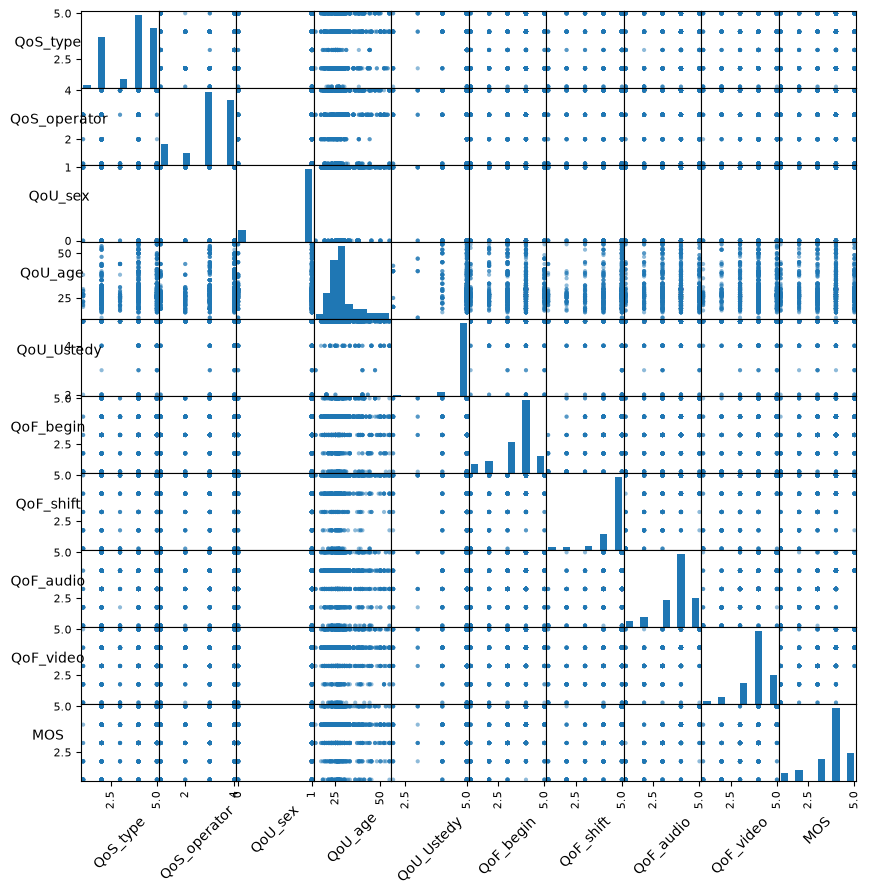

In [37]:
# Other columns' correlation
corr_plot_cols_sub = ['QoS_type','QoS_operator',
                  'QoU_sex', 'QoU_age',
                  'QoU_Ustedy', 'QoF_begin', 'QoF_shift',
                  'QoF_audio', 'QoF_video',
                  'MOS']
sm = scatter_matrix(df[corr_plot_cols_sub],
                   figsize=(10,10))
# sm = scatter_matrix(df.drop(columns=['id', 'user_id']), figsize=(20,20))
visualization.rotate_labels(sm)
plt.show()

In [38]:
corr_matrix_sub = df[corr_plot_cols_sub].corr().round(2)
corr_matrix_sub

,QoS_type,QoS_operator,QoU_sex,QoU_age,QoU_Ustedy,QoF_begin,QoF_shift,QoF_audio,QoF_video,MOS
QoS_type,1.00,0.35,-0.02,0.08,-0.05,0.24,0.18,0.12,0.16,0.15
QoS_operator,0.35,1.00,0.03,0.10,-0.08,0.18,0.17,0.01,-0.00,0.05
QoU_sex,-0.02,0.03,1.00,-0.02,0.02,0.05,0.01,0.08,0.05,0.06
QoU_age,0.08,0.10,-0.02,1.00,-0.14,-0.01,0.08,-0.06,-0.02,-0.04
QoU_Ustedy,-0.05,-0.08,0.02,-0.14,1.00,-0.01,-0.00,0.08,0.00,0.06
QoF_begin,0.24,0.18,0.05,-0.01,-0.01,1.00,0.53,0.44,0.46,0.59
QoF_shift,0.18,0.17,0.01,0.08,-0.00,0.53,1.00,0.57,0.55,0.63
QoF_audio,0.12,0.01,0.08,-0.06,0.08,0.44,0.57,1.00,0.69,0.84
QoF_video,0.16,-0.00,0.05,-0.02,0.00,0.46,0.55,0.69,1.00,0.69
MOS,0.15,0.05,0.06,-0.04,0.06,0.59,0.63,0.84,0.69,1.00


Check correlation after one-hot encoding QoD_model

In [43]:
df["QoD_model"].value_counts().sort_index()

QoD_model
ARCHOS 101G9     55
D5802             1
D5803           576
GT-I9189          1
GT-I9191          1
GT-I9192          1
GT-I9193          1
GT-I9194          1
GT-I9195        338
GT-I9300        181
HTC One X+      158
HTC One_M8       24
Nexus 4          55
SM-G900F        112
SM-N9005         37
Name: count, dtype: int64

In [42]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# fit-transform the device column
encoded = ohe.fit_transform(df[["QoD_model"]])

# build a DataFrame with proper column names, aligned to df's index
device_dummies = pd.DataFrame(
    encoded,
    columns=ohe.get_feature_names_out(["QoD_model"]),
    index=df.index,
)

# concat back to original df
df_encoded = pd.concat([df, device_dummies], axis=1)

# correlation among the device dummy columns
corr = df_encoded[device_dummies.columns].corr()
corr

,QoD_model_ARCHOS 101G9,QoD_model_D5802,QoD_model_D5803,QoD_model_GT-I9189,QoD_model_GT-I9191,QoD_model_GT-I9192,QoD_model_GT-I9193,QoD_model_GT-I9194,QoD_model_GT-I9195,QoD_model_GT-I9300,QoD_model_HTC One X+,QoD_model_HTC One_M8,QoD_model_Nexus 4,QoD_model_SM-G900F,QoD_model_SM-N9005
QoD_model_ARCHOS 101G9,1.000000,-0.004899,-0.148508,-0.004899,-0.004899,-0.004899,-0.004899,-0.004899,-0.101899,-0.070135,-0.064981,-0.024182,-0.036987,-0.053823,-0.030155
QoD_model_D5802,-0.004899,1.000000,-0.019671,-0.000649,-0.000649,-0.000649,-0.000649,-0.000649,-0.013497,-0.009290,-0.008607,-0.003203,-0.004899,-0.007129,-0.003994
QoD_model_D5803,-0.148508,-0.019671,1.000000,-0.019671,-0.019671,-0.019671,-0.019671,-0.019671,-0.409136,-0.281600,-0.260905,-0.097094,-0.148508,-0.216104,-0.121075
QoD_model_GT-I9189,-0.004899,-0.000649,-0.019671,1.000000,-0.000649,-0.000649,-0.000649,-0.000649,-0.013497,-0.009290,-0.008607,-0.003203,-0.004899,-0.007129,-0.003994
QoD_model_GT-I9191,-0.004899,-0.000649,-0.019671,-0.000649,1.000000,-0.000649,-0.000649,-0.000649,-0.013497,-0.009290,-0.008607,-0.003203,-0.004899,-0.007129,-0.003994
QoD_model_GT-I9192,-0.004899,-0.000649,-0.019671,-0.000649,-0.000649,1.000000,-0.000649,-0.000649,-0.013497,-0.009290,-0.008607,-0.003203,-0.004899,-0.007129,-0.003994
QoD_model_GT-I9193,-0.004899,-0.000649,-0.019671,-0.000649,-0.000649,-0.000649,1.000000,-0.000649,-0.013497,-0.009290,-0.008607,-0.003203,-0.004899,-0.007129,-0.003994
QoD_model_GT-I9194,-0.004899,-0.000649,-0.019671,-0.000649,-0.000649,-0.000649,-0.000649,1.000000,-0.013497,-0.009290,-0.008607,-0.003203,-0.004899,-0.007129,-0.003994
QoD_model_GT-I9195,-0.101899,-0.013497,-0.409136,-0.013497,-0.013497,-0.013497,-0.013497,-0.013497,1.000000,-0.193221,-0.179022,-0.066622,-0.101899,-0.148281,-0.083076
QoD_model_GT-I9300,-0.070135,-0.009290,-0.281600,-0.009290,-0.009290,-0.009290,-0.009290,-0.009290,-0.193221,1.000000,-0.123217,-0.045854,-0.070135,-0.102059,-0.057180


QoD_model_GT-I9195 <-> QoD_model_D5803 correlation is quite high (-0.409) because both of them are the two most popular values (GT-I9195: 338, D5803: 576)